# 5. EDA
## 1) Setup

In [1]:
from pathlib import Path
from time import perf_counter
from datetime import datetime, timezone
from itertools import combinations
from IPython.display import display
from importlib.metadata import version
import ast
import gc
import hashlib
import json
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import set_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_auc_score, log_loss, mutual_info_score
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from threadpoolctl import threadpool_limits
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

EDA_ROOT = Path.cwd()
EDA_SEED = 42
EDA_N_SPLITS = 5
EDA_CHECK_FOLDS = 3
EDA_RUN_MODEL_CHECKS = True
EDA_RUN_DOMAIN_CHECK = True
EDA_PFI_ROWS = 1500
EDA_PFI_REPEATS = 2
EDA_THREADS = min(10, os.cpu_count() or 1)
EDA_MIN_GROUP = 100
EDA_CACHE = True
EDA_RUN_MLP_CHECKS = True
EDA_KNN_MAX_DONORS = 3000
EDA_KNN_NEIGHBORS = 7
EDA_IMPUTER_MAX_ITER = 5
EDA_MLP_EPOCH_CAP = 60

if not (EDA_ROOT / 'data' / 'training_set_features.csv').is_file():
    matches = [p for p in [EDA_ROOT / '2_H1N1', EDA_ROOT.parent]
               if (p / 'data' / 'training_set_features.csv').is_file()]
    if len(matches) != 1:
        raise FileNotFoundError('Place eda.ipynb in the competition folder beside data/ and the saved .npy/.json/.csv assets, then run there.')
    EDA_ROOT = matches[0]

eda_out = EDA_ROOT / 'eda_results'
eda_out.mkdir(exist_ok=True)
eda_cache_dir = eda_out / '_cache'
eda_cache_dir.mkdir(exist_ok=True)
eda_tables, eda_files, eda_notes, eda_timing = {}, [], [], []
eda_started = perf_counter()
eda_versions = {p: version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'xgboost', 'catboost']}
set_config(transform_output='default')
try:
    import torch
    eda_cuda = torch.cuda.is_available()
except ImportError:
    eda_cuda = False
eda_xgb_device = 'cuda' if eda_cuda else 'cpu'

def eda_note(message):
    eda_notes.append(message)
    print(message, flush=True)

def eda_report(name, table, n=15):
    frame = table.copy()
    eda_tables[name] = frame
    path = eda_out / f'{name}.csv'
    frame.to_csv(path, index=False)
    if path not in eda_files:
        eda_files.append(path)
    print(f'\n{name}: {len(frame)} rows', flush=True)
    if n and not frame.empty:
        display(frame.head(n).round(6))

def eda_save_figure(name):
    plt.tight_layout()
    path = eda_out / f'{name}.png'
    plt.savefig(path, dpi=130, bbox_inches='tight')
    eda_files.append(path)
    plt.show()
    plt.close()

def eda_levels(series):
    values = series.astype(float) if pd.api.types.is_numeric_dtype(series) else series
    return values.astype('string').fillna('__MISSING__')

def eda_auc2(truth, probability):
    truth, probability = np.asarray(truth), np.asarray(probability)
    return np.asarray([roc_auc_score(truth[:, j], probability[:, j])
                       if np.unique(truth[:, j]).size == 2 else np.nan
                       for j in range(truth.shape[1])])

def eda_json(path):
    return json.loads(path.read_text(encoding='utf-8-sig'))

eda_note(f'Folder: {EDA_ROOT}\nAdditional model checks: {EDA_CHECK_FOLDS} folds; no HPO. XGBoost device: {eda_xgb_device}.')
eda_note('Original assets and submissions are read-only. All new outputs go to eda_results/. No rows are automatically removed.')
eda_note('Reused HPO folds provide exploratory model-selection scores, not an independent test estimate. The saved OOF arrays have no row IDs; consistency checks follow.')

eda_note('New checks: employment-context encoding, numeric imputation, per-target class weights and MLP scaling. KNN donor rows and MLP epochs have explicit screening caps in Setup; no HPO is added.')


Folder: c:\Users\yana\Desktop\Library\AI\ai-competitions\2_H1N1
Additional model checks: 3 folds; no HPO. XGBoost device: cuda.
Original assets and submissions are read-only. All new outputs go to eda_results/. No rows are automatically removed.
Reused HPO folds provide exploratory model-selection scores, not an independent test estimate. The saved OOF arrays have no row IDs; consistency checks follow.
New checks: employment-context encoding, numeric imputation, per-target class weights and MLP scaling. KNN donor rows and MLP epochs have explicit screening caps in Setup; no HPO is added.


## 2) Load and verify saved assets

In [2]:
eda_targets = ['h1n1_vaccine', 'seasonal_vaccine']
eda_models = ['xgb', 'catboost', 'mlp']
eda_required = [
    'data/training_set_features.csv', 'data/training_set_labels.csv',
    'data/test_set_features.csv', 'data/submission_format.csv',
    'cv_results.csv', 'ensemble_selection.json', 'submission.csv',
    'catboost_refit_iterations.json',
] + [f'{m}_{suffix}' for m in eda_models
     for suffix in ['oof.npy', 'best_params.json', 'hpo_trials.csv']
] + [f'base_{m}_hpo.csv' for m in eda_models]
eda_missing_files = [f for f in eda_required if not (EDA_ROOT / f).is_file()]
if eda_missing_files:
    raise FileNotFoundError('Missing saved assets: ' + ', '.join(eda_missing_files))

eda_features = pd.read_csv(EDA_ROOT / 'data/training_set_features.csv')
eda_labels = pd.read_csv(EDA_ROOT / 'data/training_set_labels.csv')
eda_test_features = pd.read_csv(EDA_ROOT / 'data/test_set_features.csv')
eda_format = pd.read_csv(EDA_ROOT / 'data/submission_format.csv')
for frame in [eda_features, eda_labels, eda_test_features, eda_format]:
    if frame['respondent_id'].isna().any() or not frame['respondent_id'].is_unique:
        raise ValueError('Input respondent_id values must be present and unique.')
if set(eda_features.respondent_id) != set(eda_labels.respondent_id):
    raise ValueError('Training feature and target IDs differ.')
if set(eda_test_features.respondent_id) != set(eda_format.respondent_id):
    raise ValueError('Test and submission-format IDs differ.')
eda_ids = eda_features.respondent_id.to_numpy()
eda_test_ids = eda_test_features.respondent_id.to_numpy()
eda_X = eda_features.drop(columns='respondent_id').reset_index(drop=True)
eda_T = eda_test_features.loc[:, eda_X.columns].reset_index(drop=True)
eda_y = eda_labels.set_index('respondent_id').loc[eda_ids, eda_targets].reset_index(drop=True)
if not eda_y.isin([0, 1]).all().all():
    raise ValueError('Targets must be binary and nonmissing.')
eda_y = eda_y.astype(np.int32)
eda_cat = eda_X.select_dtypes(exclude='number').columns.tolist()
eda_opinions = [c for c in eda_X if c.startswith('opinion_')]
eda_cv = list(KFold(EDA_N_SPLITS, shuffle=True, random_state=EDA_SEED).split(eda_X))
if not 1 <= EDA_CHECK_FOLDS <= EDA_N_SPLITS:
    raise ValueError('EDA_CHECK_FOLDS must be between 1 and EDA_N_SPLITS.')
for f, (_, va) in enumerate(eda_cv):
    if (eda_y.iloc[va].nunique() != 2).any():
        raise ValueError(f'Fold {f + 1} does not contain both classes per target.')

def eda_validate_probs(values, n, name):
    array = np.asarray(values, dtype=float)
    if array.shape != (n, 2) or not np.isfinite(array).all():
        raise ValueError(f'{name}: expected a finite ({n}, 2) probability matrix.')
    if ((array < 0) | (array > 1)).any():
        raise ValueError(f'{name}: probability outside [0, 1].')
    return array

def eda_read_submission(filename):
    frame = pd.read_csv(EDA_ROOT / filename)
    if frame.respondent_id.duplicated().any() or set(frame.respondent_id) != set(eda_test_ids):
        raise ValueError(f'{filename}: test IDs do not match.')
    return eda_validate_probs(frame.set_index('respondent_id').loc[eda_test_ids, eda_targets], len(eda_T), filename)

eda_oof = {m: eda_validate_probs(np.load(EDA_ROOT / f'{m}_oof.npy', allow_pickle=False), len(eda_X), m)
           for m in eda_models}
eda_test_pred = {m: eda_read_submission(f'base_{m}_hpo.csv') for m in eda_models}
eda_params = {m: eda_json(EDA_ROOT / f'{m}_best_params.json') for m in eda_models}
eda_trials = {m: pd.read_csv(EDA_ROOT / f'{m}_hpo_trials.csv') for m in eda_models}
eda_saved_cv = pd.read_csv(EDA_ROOT / 'cv_results.csv').set_index('model')
eda_selection = eda_json(EDA_ROOT / 'ensemble_selection.json')
eda_order = eda_selection['model_order']
if set(eda_order) != set(eda_models):
    raise ValueError('The saved model order does not match xgb/catboost/mlp.')
eda_saved_weights = dict(zip(eda_order, eda_selection['weights']))
eda_weights = np.asarray([eda_saved_weights[m] for m in eda_models], dtype=float)
if not np.isfinite(eda_weights).all() or (eda_weights < 0).any() or eda_weights.sum() <= 0:
    raise ValueError('Invalid saved ensemble weights.')
eda_stack = np.stack([eda_oof[m] for m in eda_models])
eda_test_stack = np.stack([eda_test_pred[m] for m in eda_models])
eda_oof['submitted'] = np.average(eda_stack, axis=0, weights=eda_weights)
eda_submitted_test = eda_read_submission('submission.csv')
eda_reconstructed_test = np.average(eda_test_stack, axis=0, weights=eda_weights)
if not np.allclose(eda_submitted_test, eda_reconstructed_test, rtol=1e-6, atol=1e-7):
    raise ValueError('submission.csv and the saved base predictions/weights do not reconstruct. Check for files mixed across runs.')

eda_audit = []
for name in eda_models + ['submitted']:
    scores = np.stack([eda_auc2(eda_y.iloc[va], eda_oof[name][va]) for _, va in eda_cv])
    saved_name = eda_selection['selected_ensemble'] if name == 'submitted' else name
    expected = float(eda_saved_cv.loc[saved_name, 'mean_cv_auc'])
    observed = float(scores.mean())
    eda_audit.append({'model': name, 'mean_cv_auc': observed, 'h1n1_auc': scores[:, 0].mean(),
                      'seasonal_auc': scores[:, 1].mean(), 'saved_cv_auc': expected,
                      'absolute_difference': abs(expected - observed)})
    per_target_expected = eda_saved_cv.loc[saved_name, ['h1n1_auc', 'seasonal_auc']].to_numpy(dtype=float)
    if abs(expected - observed) > 2e-6 or np.max(np.abs(per_target_expected - scores.mean(axis=0))) > 2e-6:
        raise ValueError(f'{name}: saved CV score was not reproduced. Keep the original training-row order and use matching files, EDA_SEED and EDA_N_SPLITS.')
eda_report('02_asset_score_audit', pd.DataFrame(eda_audit).sort_values('mean_cv_auc', ascending=False))
eda_note(f'Saved selected ensemble: {eda_selection["selected_ensemble"]}; weights in {eda_models} order: {eda_weights.tolist()}')
eda_note('Counts, score reconstruction and test-ID alignment passed. Without original per-row OOF IDs/hashes, these are consistency checks, not proof of row provenance.')

eda_hasher = hashlib.sha256()
eda_inventory = []
for relative in eda_required:
    path = EDA_ROOT / relative
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    eda_hasher.update((relative + digest).encode())
    eda_inventory.append({'file': relative, 'bytes': path.stat().st_size, 'sha256': digest})
eda_fingerprint = eda_hasher.hexdigest()
eda_report('02_input_manifest', pd.DataFrame(eda_inventory), 5)
eda_export_oof = pd.DataFrame({'respondent_id': eda_ids})
for j, target in enumerate(eda_targets):
    eda_export_oof[target] = eda_y[target]
    for name, probability in eda_oof.items():
        eda_export_oof[f'{name}__{target}'] = probability[:, j]
eda_report('02_aligned_oof_predictions', eda_export_oof, 0)
print(f'Loaded {eda_X.shape} training features and {eda_T.shape} test features; no main notebook execution.', flush=True)



02_asset_score_audit: 4 rows


,model,mean_cv_auc,h1n1_auc,seasonal_auc,saved_cv_auc,absolute_difference
1,catboost,0.868229,0.871670,0.864789,0.868229,0.0
3,submitted,0.864927,0.864899,0.864955,0.864927,0.0
0,xgb,0.852033,0.842141,0.861925,0.852033,0.0
2,mlp,0.848605,0.838931,0.858279,0.848605,0.0


Saved selected ensemble: xgb_catboost; weights in ['xgb', 'catboost', 'mlp'] order: [1.0, 1.0, 0.0]
Counts, score reconstruction and test-ID alignment passed. Without original per-row OOF IDs/hashes, these are consistency checks, not proof of row provenance.

02_input_manifest: 20 rows


,file,bytes,sha256
0,data/training_set_features.csv,4619138,9a805f24b45fd9bd0b52cedf7cab0ccc62b512372f0015...
1,data/training_set_labels.csv,256004,0ad33a821b96666a0dbfafc4e6fe23969ded212c6b55eb...
2,data/test_set_features.csv,4633317,fbb8e4f208c222a1559c701dd351e5db8fc12c1671393a...
3,data/submission_format.csv,373956,9a6cfd8e7d75f4d0586f59ec50d27947c5c2d546e25db8...
4,cv_results.csv,496,b7f62fa59ea1c4a35717c0ab4825c08be98b7a9d6b99a1...



02_aligned_oof_predictions: 26707 rows
Loaded (26707, 35) training features and (26708, 35) test features; no main notebook execution.


## 3) Model contribution and target-specific soft voting

In [3]:
eda_candidate_weights = {
    'xgb_only': [1, 0, 0], 'catboost_only': [0, 1, 0], 'mlp_only': [0, 0, 1],
    'submitted': eda_weights.tolist(),
    'equal_xgb_catboost': [1, 1, 0], 'equal_catboost_mlp': [0, 1, 1],
    'equal_xgb_mlp': [1, 0, 1], 'equal_all_three': [1, 1, 1],
    'catboost_75_xgb_25': [1, 3, 0], 'catboost_90_xgb_10': [1, 9, 0],
    'catboost_90_mlp_10': [0, 9, 1],
}
eda_weight_matrices = {name: np.repeat((np.asarray(w) / np.sum(w))[:, None], 2, axis=1)
                      for name, w in eda_candidate_weights.items()}
eda_weight_matrices['catboost_h1n1__equal_trees_seasonal'] = np.array([[0, .5], [1, .5], [0, 0]])
eda_weight_rows = []
for a in range(5):
    for b in range(5 - a):
        w = np.array([a, b, 4 - a - b], dtype=float) / 4
        probability = np.tensordot(w, eda_stack, axes=1)
        fold_scores = np.stack([eda_auc2(eda_y.iloc[va], probability[va]) for _, va in eda_cv])
        for j, target in enumerate(eda_targets):
            eda_weight_rows.append({'target': target, 'xgb_weight': w[0], 'catboost_weight': w[1],
                                    'mlp_weight': w[2], 'mean_cv_auc': fold_scores[:, j].mean()})
eda_weight_grid = pd.DataFrame(eda_weight_rows)
eda_grid_best = eda_weight_grid.sort_values('mean_cv_auc', ascending=False).drop_duplicates('target').set_index('target')
eda_weight_matrices['coarse_target_specific'] = np.stack([
    eda_grid_best.loc[t, ['xgb_weight', 'catboost_weight', 'mlp_weight']].to_numpy(dtype=float)
    for t in eda_targets
], axis=1)
eda_report('03_weight_grid', eda_weight_grid.sort_values(['target', 'mean_cv_auc'], ascending=[True, False]), 10)
eda_report('03_selected_target_weights', eda_grid_best.reset_index())

eda_reference_folds = np.stack([eda_auc2(eda_y.iloc[va], eda_oof['submitted'][va]) for _, va in eda_cv])
eda_candidate_rows, eda_candidate_fold_rows = [], []
for name, weights in eda_weight_matrices.items():
    probability = np.sum(eda_stack * weights[:, None, :], axis=0)
    scores = np.stack([eda_auc2(eda_y.iloc[va], probability[va]) for _, va in eda_cv])
    delta = scores - eda_reference_folds
    eda_candidate_rows.append({
        'candidate': name, 'mean_cv_auc': scores.mean(), 'h1n1_auc': scores[:, 0].mean(),
        'seasonal_auc': scores[:, 1].mean(), 'delta_vs_submitted': delta.mean(),
        'improved_folds': int((delta.mean(axis=1) > 0).sum()),
        'fold_delta_std': delta.mean(axis=1).std(ddof=1),
    })
    for f in range(EDA_N_SPLITS):
        eda_candidate_fold_rows.append({'candidate': name, 'fold': f + 1, 'macro_auc': scores[f].mean(),
                                        'h1n1_auc': scores[f, 0], 'seasonal_auc': scores[f, 1],
                                        'delta_vs_submitted': delta[f].mean()})
eda_candidates = pd.DataFrame(eda_candidate_rows).sort_values('mean_cv_auc', ascending=False)
eda_report('03_candidate_comparison', eda_candidates, 20)
eda_report('03_candidate_fold_scores', pd.DataFrame(eda_candidate_fold_rows), 5)
eda_note('The grid is a coarse weight-selection diagnostic on existing OOF predictions, not fresh/nested validation. Small gains can be selection noise.')

eda_candidate_dir = eda_out / 'candidates'
eda_candidate_dir.mkdir(exist_ok=True)
for name in ['catboost_only', 'coarse_target_specific']:
    probability = np.sum(eda_test_stack * eda_weight_matrices[name][:, None, :], axis=0)
    predicted = pd.DataFrame(probability, columns=eda_targets, index=eda_test_ids)
    frame = eda_format.copy()
    frame[eda_targets] = predicted.loc[frame.respondent_id, eda_targets].to_numpy()
    path = eda_candidate_dir / f'{name}.csv'
    frame.to_csv(path, index=False)
    eda_files.append(path)
path = eda_candidate_dir / 'weights.json'
path.write_text(json.dumps({name: weights.tolist() for name, weights in eda_weight_matrices.items()}, indent=2))
eda_files.append(path)
eda_note('Two candidate CSVs saved under eda_results/candidates/. Your submitted files were not replaced; leaderboard improvement is not established.')



03_weight_grid: 30 rows


,target,xgb_weight,catboost_weight,mlp_weight,mean_cv_auc
8,h1n1_vaccine,0.00,1.00,0.00,0.871670
6,h1n1_vaccine,0.00,0.75,0.25,0.870230
16,h1n1_vaccine,0.25,0.75,0.00,0.870200
14,h1n1_vaccine,0.25,0.50,0.25,0.865219
22,h1n1_vaccine,0.50,0.50,0.00,0.864899
4,h1n1_vaccine,0.00,0.50,0.50,0.864614
20,h1n1_vaccine,0.50,0.25,0.25,0.856208
12,h1n1_vaccine,0.25,0.25,0.50,0.855816
26,h1n1_vaccine,0.75,0.25,0.00,0.855715
2,h1n1_vaccine,0.00,0.25,0.75,0.854476



03_selected_target_weights: 2 rows


,target,xgb_weight,catboost_weight,mlp_weight,mean_cv_auc
0,h1n1_vaccine,0.00,1.00,0.0,0.871670
1,seasonal_vaccine,0.25,0.75,0.0,0.865273



03_candidate_comparison: 13 rows


,candidate,mean_cv_auc,h1n1_auc,seasonal_auc,delta_vs_submitted,improved_folds,fold_delta_std
12,coarse_target_specific,0.868471,0.871670,0.865273,0.003544,5,0.000955
9,catboost_90_xgb_10,0.868321,0.871560,0.865081,0.003394,5,0.000773
11,catboost_h1n1__equal_trees_seasonal,0.868312,0.871670,0.864955,0.003385,5,0.000964
10,catboost_90_mlp_10,0.868309,0.871608,0.865009,0.003382,5,0.000730
1,catboost_only,0.868229,0.871670,0.864789,0.003302,5,0.000953
8,catboost_75_xgb_25,0.867736,0.870200,0.865273,0.002809,5,0.000495
4,equal_xgb_catboost,0.864927,0.864899,0.864955,0.000000,0,0.000000
3,submitted,0.864927,0.864899,0.864955,0.000000,0,0.000000
5,equal_catboost_mlp,0.864285,0.864614,0.863955,-0.000642,0,0.000303
7,equal_all_three,0.861937,0.859630,0.864245,-0.002990,0,0.000515



03_candidate_fold_scores: 65 rows


,candidate,fold,macro_auc,h1n1_auc,seasonal_auc,delta_vs_submitted
0,xgb_only,1,0.851914,0.839731,0.864097,-0.014320
1,xgb_only,2,0.849849,0.835245,0.864452,-0.013012
2,xgb_only,3,0.852300,0.845568,0.859033,-0.013248
3,xgb_only,4,0.850237,0.844139,0.856335,-0.012847
4,xgb_only,5,0.855867,0.846023,0.865710,-0.011040


The grid is a coarse weight-selection diagnostic on existing OOF predictions, not fresh/nested validation. Small gains can be selection noise.
Two candidate CSVs saved under eda_results/candidates/. Your submitted files were not replaced; leaderboard improvement is not established.


## 4) HPO results and compute efficiency

In [4]:
eda_hpo_summary, eda_best_trials = [], {}
for name, table in eda_trials.items():
    completed = table.loc[table.state.astype(str).str.upper().eq('COMPLETE')].copy()
    if completed.empty:
        raise ValueError(f'No completed {name} trials in the saved trial table.')
    completed = completed.sort_values(['value', 'number'], ascending=[False, True])
    best = completed.iloc[0]
    eda_best_trials[name] = best
    for key, value in eda_params[name].items():
        observed = best.get(f'params_{key}')
        equal = (np.isclose(float(observed), float(value)) if isinstance(value, (int, float))
                 else str(observed) == str(value))
        if not equal:
            raise ValueError(f'{name}: best_params.json and the best COMPLETE trial disagree on {key}.')
    if 'duration' in completed:
        completed['seconds'] = pd.to_timedelta(completed.duration).dt.total_seconds()
    else:
        completed['seconds'] = (pd.to_datetime(completed.datetime_complete) - pd.to_datetime(completed.datetime_start)).dt.total_seconds()
    near_best = completed.loc[completed.value >= best.value - 0.0005].sort_values('seconds')
    eda_hpo_summary.append({'model': name, 'complete': len(completed),
                            'pruned': int(table.state.astype(str).str.upper().eq('PRUNED').sum()),
                            'best_trial': int(best.number), 'best_cv_auc': best.value,
                            'median_complete_seconds': completed.seconds.median(),
                            'fastest_within_0_0005_trial': int(near_best.iloc[0].number),
                            'fastest_within_0_0005_seconds': near_best.iloc[0].seconds})
    wanted = ['number', 'value', 'seconds'] + [c for c in completed if c.startswith('params_')]
    eda_report(f'04_{name}_top_trials', completed[wanted], 5)
    eda_report(f'04_{name}_all_trials', table, 0)
eda_report('04_hpo_efficiency', pd.DataFrame(eda_hpo_summary))
eda_note('The 0.0005 near-best tolerance is a compute-screening convention, not a statistical equivalence test.')

def eda_parse_list(value):
    return ast.literal_eval(value) if isinstance(value, str) else value

raw = eda_best_trials['catboost'].get('user_attrs_best_iterations')
if isinstance(raw, str):
    eda_cat_counts = np.asarray(eda_parse_list(raw), dtype=int)
    if eda_cat_counts.shape != (EDA_N_SPLITS, 2):
        raise ValueError('Saved CatBoost per-fold iteration counts have an unexpected shape.')
else:
    counts = eda_json(EDA_ROOT / 'catboost_refit_iterations.json')
    eda_cat_counts = np.tile([counts[t] for t in eda_targets], (EDA_N_SPLITS, 1))
    eda_note('Per-fold CatBoost iteration counts unavailable: using saved full-refit counts as fixed diagnostic settings.')
if (eda_cat_counts < 1).any():
    raise ValueError('CatBoost iteration counts must be positive.')
eda_report('04_catboost_iterations', pd.DataFrame({
    'fold': np.arange(1, EDA_N_SPLITS + 1),
    'h1n1_iterations': eda_cat_counts[:, 0], 'seasonal_iterations': eda_cat_counts[:, 1],
}))
eda_note('Additional CatBoost fits will reuse these fixed counts. No pilot fits or early-stopping searches are rerun.')



04_xgb_top_trials: 15 rows


,number,value,seconds,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample
10,10,0.852033,22.057186,0.928433,0.0,0.012152,6,9.657382,900,0.1,0.858861,0.686813
19,19,0.851968,12.333697,0.983232,0.0,0.020342,5,6.292761,600,0.1,0.017134,0.682832
11,11,0.851708,24.498575,0.919856,0.0,0.012502,5,5.922136,1200,0.1,0.097995,0.671304
1,1,0.851525,26.524804,0.914070,0.0,0.014590,3,3.476649,2100,0.1,55.517217,0.782428
15,15,0.851102,15.982269,0.948955,0.0,0.010209,6,7.256690,600,0.1,0.114368,0.877528



04_xgb_all_trials: 20 rows

04_catboost_top_trials: 7 rows


,number,value,seconds,params_bagging_temperature,params_depth,params_l2_leaf_reg,params_learning_rate
6,6,0.868229,1347.074803,1.804963,6,19.982682,0.012576
0,0,0.868211,272.188759,1.197317,5,12.057126,0.089272
4,4,0.868141,551.436201,0.582458,5,4.345454,0.033478
3,3,0.867946,918.907906,0.366809,7,1.855998,0.016306
2,2,0.867727,412.219963,1.939820,6,1.072521,0.051059



04_catboost_all_trials: 7 rows

04_mlp_top_trials: 17 rows


...


04_mlp_all_trials: 20 rows

04_hpo_efficiency: 3 rows


,model,complete,pruned,best_trial,best_cv_auc,median_complete_seconds,fastest_within_0_0005_trial,fastest_within_0_0005_seconds
0,xgb,15,5,10,0.852033,24.013046,19,12.333697
1,catboost,7,0,6,0.868229,551.436201,0,272.188759
2,mlp,17,3,12,0.848605,57.092795,17,46.150982


The 0.0005 near-best tolerance is a compute-screening convention, not a statistical equivalence test.

04_catboost_iterations: 5 rows


,fold,h1n1_iterations,seasonal_iterations
0,1,1999,1921
1,2,2000,1942
2,3,1846,1995
3,4,979,1166
4,5,1825,1990


Additional CatBoost fits will reuse these fixed counts. No pilot fits or early-stopping searches are rerun.


## 5) Feature inventory and response-code audit

In [5]:
eda_profile = pd.DataFrame({
    'feature': eda_X.columns, 'dtype': eda_X.dtypes.astype(str).to_numpy(),
    'n_unique': eda_X.nunique().to_numpy(), 'missing_train': eda_X.isna().mean().to_numpy(),
    'missing_test': eda_T.isna().mean().to_numpy(),
    'largest_level_share': [eda_levels(eda_X[c]).value_counts(normalize=True).max() for c in eda_X],
}).sort_values('missing_train', ascending=False)
eda_report('05_feature_profile', eda_profile, 40)
eda_allowed = {c: list(range(4)) for c in ['h1n1_concern', 'household_adults', 'household_children'] if c in eda_X}
if 'h1n1_knowledge' in eda_X:
    eda_allowed['h1n1_knowledge'] = [0, 1, 2]
eda_allowed.update({c: list(range(1, 6)) for c in eda_opinions})
eda_binary_names = [c for c in eda_X if c.startswith('behavioral_')] + [
    'doctor_recc_h1n1', 'doctor_recc_seasonal', 'chronic_med_condition',
    'child_under_6_months', 'health_worker', 'health_insurance',
]
eda_allowed.update({c: [0, 1] for c in eda_binary_names if c in eda_X})
eda_invalid = []
for name, frame in [('train', eda_X), ('test', eda_T)]:
    for c, values in eda_allowed.items():
        bad = frame[c].notna() & ~frame[c].isin(values)
        eda_invalid.append({'dataset': name, 'feature': c, 'invalid_n': int(bad.sum()),
                            'invalid_values': '|'.join(map(str, frame.loc[bad, c].unique()))})
eda_report('05_response_code_audit', pd.DataFrame(eda_invalid), 0)
display(pd.DataFrame(eda_invalid).query('invalid_n > 0'))
eda_schema = pd.DataFrame({'feature': list(eda_allowed), 'allowed_codes': [str(x) for x in eda_allowed.values()]})
eda_report('05_expected_numeric_codes', eda_schema, 0)
eda_signature = pd.util.hash_pandas_object(eda_X, index=False)
eda_duplicate = eda_y.assign(profile_hash=eda_signature).groupby('profile_hash').agg(
    n=('h1n1_vaccine', 'size'), h1n1_unique=('h1n1_vaccine', 'nunique'),
    seasonal_unique=('seasonal_vaccine', 'nunique'),
).query('n > 1').reset_index()
eda_report('05_duplicate_profiles', eda_duplicate)
eda_note('Respondent ID is excluded. Opinion code 3 means do not know; household count 3 is top-coded. Rare valid answers are not automatically outliers.')
eda_note('Identical survey answers can belong to different people; a duplicate feature profile is not proof of a duplicate person.')



05_feature_profile: 35 rows


,feature,dtype,n_unique,missing_train,missing_test,largest_level_share
34,employment_occupation,str,23,0.504362,0.502696,0.504362
33,employment_industry,str,21,0.499120,0.497042,0.499120
14,health_insurance,float64,2,0.459580,0.457840,0.475418
25,income_poverty,str,3,0.165612,0.168377,0.478414
10,doctor_recc_seasonal,float64,2,0.080878,0.080875,0.616056
9,doctor_recc_h1n1,float64,2,0.080878,0.080875,0.716629
27,rent_or_own,str,2,0.076459,0.076232,0.701539
28,employment_status,str,3,0.054780,0.055077,0.507732
26,marital_status,str,2,0.052720,0.053991,0.507545
22,education,str,4,0.052683,0.052681,0.378066



05_response_code_audit: 46 rows


,dataset,feature,invalid_n,invalid_values



05_expected_numeric_codes: 23 rows

05_duplicate_profiles: 0 rows
Respondent ID is excluded. Opinion code 3 means do not know; household count 3 is top-coded. Rare valid answers are not automatically outliers.
Identical survey answers can belong to different people; a duplicate feature profile is not proof of a duplicate person.


## 6) Relationship between the two labels


06_joint_labels: 4 rows


,h1n1,seasonal,n,share
0,0,0,13295,0.497810
1,0,1,7738,0.289737
2,1,0,977,0.036582
3,1,1,4697,0.175871



06_conditional_label_rates: 4 rows


,target,condition,n,positive_rate
0,h1n1_vaccine,seasonal_vaccine=0,14272,0.068456
1,h1n1_vaccine,seasonal_vaccine=1,12435,0.377724
2,seasonal_vaccine,h1n1_vaccine=0,21033,0.367898
3,seasonal_vaccine,h1n1_vaccine=1,5674,0.827811



06_label_association: 1 rows


,phi,mutual_information_bits
0,0.377143,0.108378



06_label_association_by_group: 14 rows


,feature,level,n,phi,h1n1_rate,seasonal_rate
0,age_group,18 - 34 Years,5215,0.431128,0.190029,0.284564
1,age_group,35 - 44 Years,3848,0.418172,0.197765,0.362526
2,age_group,45 - 54 Years,5238,0.424586,0.194731,0.401298
3,age_group,55 - 64 Years,5563,0.418744,0.242855,0.511235
4,age_group,65+ Years,6843,0.265859,0.226655,0.673681
5,doctor_recc_h1n1,0.0,19139,0.305833,0.136371,0.422854
6,doctor_recc_h1n1,1.0,5408,0.429091,0.532359,0.662167
7,doctor_recc_h1n1,__MISSING__,2160,0.283369,0.085648,0.352315
8,doctor_recc_seasonal,0.0,16453,0.355650,0.162280,0.346259
9,doctor_recc_seasonal,1.0,8094,0.305251,0.348283,0.738448


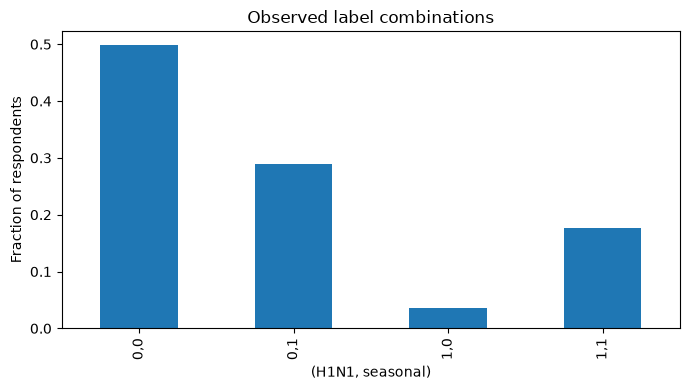

Label association is descriptive, not causal. The other true label is unavailable at test time and must not be inserted as an ordinary predictor.


In [6]:
eda_joint = pd.crosstab(eda_y.iloc[:, 0], eda_y.iloc[:, 1]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
eda_joint_table = pd.DataFrame([{'h1n1': h, 'seasonal': s, 'n': int(eda_joint.loc[h, s]),
                                 'share': eda_joint.loc[h, s] / len(eda_y)}
                                for h in [0, 1] for s in [0, 1]])
eda_report('06_joint_labels', eda_joint_table)
eda_conditional = []
for a, b in [eda_targets, eda_targets[::-1]]:
    for value in [0, 1]:
        mask = eda_y[b].eq(value)
        eda_conditional.append({'target': a, 'condition': f'{b}={value}', 'n': int(mask.sum()),
                                'positive_rate': eda_y.loc[mask, a].mean()})
eda_report('06_conditional_label_rates', pd.DataFrame(eda_conditional))
eda_report('06_label_association', pd.DataFrame([{
    'phi': eda_y.iloc[:, 0].corr(eda_y.iloc[:, 1]),
    'mutual_information_bits': mutual_info_score(eda_y.iloc[:, 0], eda_y.iloc[:, 1]) / np.log(2),
}]))
eda_within = []
for c in ['age_group', 'doctor_recc_h1n1', 'doctor_recc_seasonal', 'health_worker']:
    if c not in eda_X:
        continue
    levels = eda_levels(eda_X[c])
    for level, idx in levels.groupby(levels, observed=True).groups.items():
        part = eda_y.loc[idx]
        if len(part) >= EDA_MIN_GROUP:
            eda_within.append({'feature': c, 'level': level, 'n': len(part),
                               'phi': part.iloc[:, 0].corr(part.iloc[:, 1]) if (part.nunique() == 2).all() else np.nan,
                               'h1n1_rate': part.iloc[:, 0].mean(), 'seasonal_rate': part.iloc[:, 1].mean()})
eda_report('06_label_association_by_group', pd.DataFrame(eda_within), 30)
eda_joint_table.assign(pair=lambda t: t.h1n1.astype(str) + ',' + t.seasonal.astype(str)).plot.bar(
    x='pair', y='share', legend=False, figsize=(7, 4), title='Observed label combinations',
)
plt.xlabel('(H1N1, seasonal)')
plt.ylabel('Fraction of respondents')
eda_save_figure('06_joint_labels')
eda_note('Label association is descriptive, not causal. The other true label is unavailable at test time and must not be inserted as an ordinary predictor.')


## 7) Missingness and response patterns


07_missingness_label_associations: 60 rows


,feature,target,n_missing,n_observed,rate_missing,rate_observed,rate_gap
5,behavioral_antiviral_meds,seasonal_vaccine,71,26636,0.676056,0.465047,0.211009
53,household_adults,seasonal_vaccine,249,26458,0.257028,0.467571,-0.210543
55,household_children,seasonal_vaccine,249,26458,0.257028,0.467571,-0.210543
4,behavioral_antiviral_meds,h1n1_vaccine,71,26636,0.408451,0.211931,0.196519
28,health_insurance,h1n1_vaccine,12274,14433,0.112759,0.297236,-0.184477
20,doctor_recc_seasonal,h1n1_vaccine,2160,24547,0.085648,0.223612,-0.137964
18,doctor_recc_h1n1,h1n1_vaccine,2160,24547,0.085648,0.223612,-0.137964
19,doctor_recc_h1n1,seasonal_vaccine,2160,24547,0.352315,0.475577,-0.123263
21,doctor_recc_seasonal,seasonal_vaccine,2160,24547,0.352315,0.475577,-0.123263
9,behavioral_face_mask,seasonal_vaccine,19,26688,0.578947,0.465528,0.113420



07_correlated_missingness: 17 rows


,feature_1,feature_2,correlation
225,doctor_recc_h1n1,doctor_recc_seasonal,1.000000
429,household_adults,household_children,1.000000
434,employment_industry,employment_occupation,0.972945
282,child_under_6_months,health_worker,0.969567
380,opinion_seas_risk,opinion_seas_sick_from_vacc,0.911906
400,education,marital_status,0.887874
357,opinion_h1n1_sick_from_vacc,opinion_seas_vacc_effective,0.885407
415,marital_status,employment_status,0.876134
369,opinion_seas_vacc_effective,opinion_seas_risk,0.867697
402,education,employment_status,0.863946



07_missing_count_rates: 6 rows


...

,feature_1,feature_2,correlation
162,doctor_recc_h1n1,doctor_recc_seasonal,0.591868
117,behavioral_large_gatherings,behavioral_outside_home,0.584085
234,opinion_h1n1_risk,opinion_seas_risk,0.564522
240,opinion_h1n1_sick_from_vacc,opinion_seas_sick_from_vacc,0.502192
227,opinion_h1n1_vacc_effective,opinion_seas_vacc_effective,0.444043
15,h1n1_concern,opinion_h1n1_risk,0.386032
16,h1n1_concern,opinion_h1n1_sick_from_vacc,0.368674
243,opinion_seas_vacc_effective,opinion_seas_risk,0.366353
102,behavioral_wash_hands,behavioral_touch_face,0.365064
64,behavioral_avoidance,behavioral_wash_hands,0.338130



07_pairwise_response_rates: 106 rows


,level_1,level_2,n,h1n1_vaccine,h1n1_vaccine_lo,h1n1_vaccine_hi,seasonal_vaccine,seasonal_vaccine_lo,seasonal_vaccine_hi,feature_1,feature_2
0,0.0,0.0,15659,0.145986,0.140543,0.151604,0.345871,0.338460,0.353358,doctor_recc_h1n1,doctor_recc_seasonal
1,0.0,1.0,3480,0.093103,0.083893,0.103212,0.769253,0.754962,0.782950,doctor_recc_h1n1,doctor_recc_seasonal
2,1.0,0.0,794,0.483627,0.449029,0.518383,0.353904,0.321419,0.387796,doctor_recc_h1n1,doctor_recc_seasonal
3,1.0,1.0,4614,0.540746,0.526338,0.555085,0.715215,0.702017,0.728054,doctor_recc_h1n1,doctor_recc_seasonal
4,__MISSING__,__MISSING__,2160,0.085648,0.074570,0.098198,0.352315,0.332448,0.372706,doctor_recc_h1n1,doctor_recc_seasonal
5,1.0,1.0,454,0.037445,0.023508,0.059144,0.096916,0.072989,0.127608,opinion_h1n1_vacc_effective,opinion_seas_vacc_effective
6,1.0,2.0,126,0.031746,0.012413,0.078787,0.095238,0.055321,0.159106,opinion_h1n1_vacc_effective,opinion_seas_vacc_effective
7,1.0,3.0,21,0.047619,0.008456,0.226698,0.190476,0.076674,0.400010,opinion_h1n1_vacc_effective,opinion_seas_vacc_effective
8,1.0,4.0,165,0.054545,0.028958,0.100403,0.315152,0.249155,0.389560,opinion_h1n1_vacc_effective,opinion_seas_vacc_effective
9,1.0,5.0,108,0.101852,0.057829,0.173227,0.675926,0.582932,0.756835,opinion_h1n1_vacc_effective,opinion_seas_vacc_effective



07_missingness_by_employment: 4 rows


,employment_status,n,employment_industry,employment_occupation,health_insurance
0,Employed,13560,0.013496,0.02382,0.439676
1,Not in Labor Force,10231,1.000000,1.00000,0.427133
2,Unemployed,1453,1.000000,1.00000,0.407433
3,__MISSING__,1463,1.000000,1.00000,0.922761


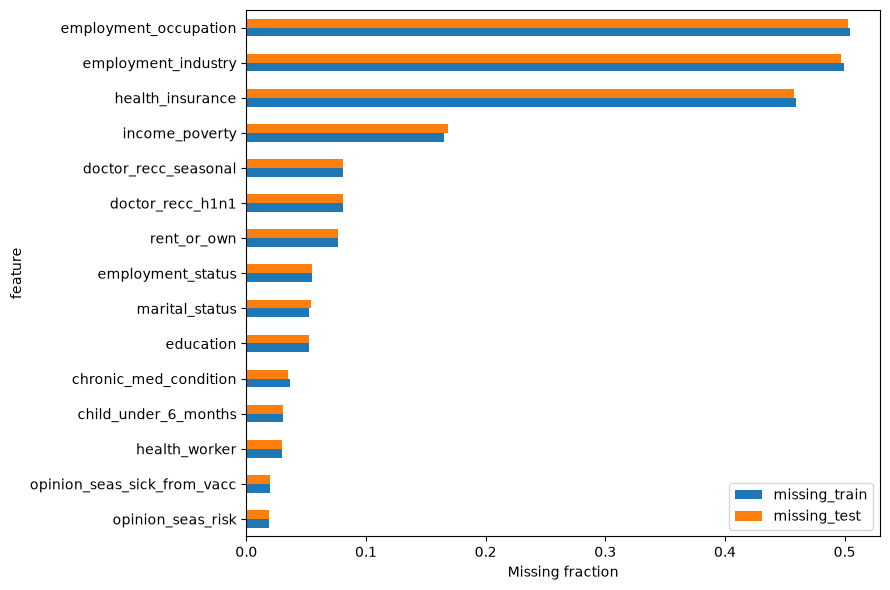

Missingness/rate associations and correlations are screens, not feature-selection criteria. Wilson intervals are descriptive and not multiple-testing-adjusted.


In [7]:
def eda_rates(keys):
    joined = pd.concat([keys.reset_index(drop=True), eda_y], axis=1)
    grouped = joined.groupby(list(keys.columns), observed=True, dropna=False)
    result = grouped.size().rename('n').to_frame()
    for target in eda_targets:
        rate, count = grouped[target].mean(), result['n']
        center = (rate + 1.96**2 / (2 * count)) / (1 + 1.96**2 / count)
        half = 1.96 * np.sqrt(rate * (1 - rate) / count + 1.96**2 / (4 * count**2)) / (1 + 1.96**2 / count)
        result[target] = rate
        result[f'{target}_lo'] = center - half
        result[f'{target}_hi'] = center + half
    return result.reset_index()

def eda_pairs(matrix):
    rows = [{'feature_1': a, 'feature_2': b, 'correlation': matrix.loc[a, b]}
            for a, b in combinations(matrix.columns, 2) if pd.notna(matrix.loc[a, b])]
    return pd.DataFrame(rows, columns=['feature_1', 'feature_2', 'correlation']).sort_values(
        'correlation', key=lambda s: s.abs(), ascending=False,
    )

eda_missing_rows = []
for c in eda_X:
    mask = eda_X[c].isna()
    if mask.any() and not mask.all():
        for target in eda_targets:
            missing_rate, observed_rate = eda_y.loc[mask, target].mean(), eda_y.loc[~mask, target].mean()
            eda_missing_rows.append({'feature': c, 'target': target, 'n_missing': int(mask.sum()),
                                     'n_observed': int((~mask).sum()), 'rate_missing': missing_rate,
                                     'rate_observed': observed_rate, 'rate_gap': missing_rate - observed_rate})
eda_missing_table = pd.DataFrame(eda_missing_rows, columns=[
    'feature', 'target', 'n_missing', 'n_observed', 'rate_missing', 'rate_observed', 'rate_gap',
]).sort_values('rate_gap', key=lambda s: s.abs(), ascending=False)
eda_report('07_missingness_label_associations', eda_missing_table, 25)
eda_report('07_correlated_missingness', eda_pairs(eda_X.isna().astype(float).corr()).query('abs(correlation) >= 0.8'))
eda_missing_count = eda_X.isna().sum(axis=1)
eda_missing_bucket = pd.cut(eda_missing_count, [-1, 0, 1, 2, 3, 5, np.inf], labels=['0', '1', '2', '3', '4-5', '6+'])
eda_report('07_missing_count_rates', eda_rates(pd.DataFrame({'missing_count': eda_missing_bucket})))
eda_response_rates = pd.concat([
    eda_rates(pd.DataFrame({'level': eda_levels(eda_X[c])})).assign(feature=c)
    for c in eda_X
], ignore_index=True)
eda_report('07_all_response_rates', eda_response_rates, 10)
eda_response_ranges = []
for feature, group in eda_response_rates.groupby('feature'):
    supported = group.loc[group.n >= EDA_MIN_GROUP]
    for target in eda_targets:
        eda_response_ranges.append({'feature': feature, 'target': target, 'supported_levels': len(supported),
                                    'rate_range': supported[target].max() - supported[target].min()})
eda_report('07_response_rate_screen', pd.DataFrame(eda_response_ranges).sort_values('rate_range', ascending=False))
eda_report('07_numeric_redundancy', eda_pairs(eda_X.select_dtypes('number').corr('spearman')))
eda_pairs_to_check = [
    ('doctor_recc_h1n1', 'doctor_recc_seasonal'),
    ('opinion_h1n1_vacc_effective', 'opinion_seas_vacc_effective'),
    ('opinion_h1n1_risk', 'opinion_seas_risk'),
    ('age_group', 'doctor_recc_h1n1'), ('age_group', 'doctor_recc_seasonal'),
]
eda_interactions = [eda_rates(pd.DataFrame({'level_1': eda_levels(eda_X[a]), 'level_2': eda_levels(eda_X[b])}))
                    .assign(feature_1=a, feature_2=b)
                    for a, b in eda_pairs_to_check if a in eda_X and b in eda_X]
if eda_interactions:
    eda_report('07_pairwise_response_rates', pd.concat(eda_interactions, ignore_index=True), 15)
if 'employment_status' in eda_X:
    fields = [c for c in ['employment_industry', 'employment_occupation', 'health_insurance'] if c in eda_X]
    grouped = eda_X[fields].isna().astype(float).assign(employment_status=eda_levels(eda_X.employment_status)).groupby('employment_status')
    eda_report('07_missingness_by_employment', pd.concat([grouped.size().rename('n'), grouped[fields].mean()], axis=1).reset_index())
eda_profile.head(15).set_index('feature')[['missing_train', 'missing_test']].iloc[::-1].plot.barh(figsize=(9, 6))
plt.xlabel('Missing fraction')
eda_save_figure('07_missingness')
eda_note('Missingness/rate associations and correlations are screens, not feature-selection criteria. Wilson intervals are descriptive and not multiple-testing-adjusted.')


## 8) Train/test distribution shift

In [8]:
eda_shift_rows = []
for c in eda_X:
    p = eda_levels(eda_X[c]).value_counts(normalize=True)
    q = eda_levels(eda_T[c]).value_counts(normalize=True)
    levels = p.index.union(q.index)
    eda_shift_rows.append({'feature': c,
                           'total_variation': .5 * (p.reindex(levels, fill_value=0) - q.reindex(levels, fill_value=0)).abs().sum(),
                           'test_unseen_fraction': (~eda_levels(eda_T[c]).isin(p.index)).mean(),
                           'missing_gap': eda_T[c].isna().mean() - eda_X[c].isna().mean()})
eda_report('08_train_test_shift', pd.DataFrame(eda_shift_rows).sort_values('total_variation', ascending=False), 35)

def eda_preprocessor(frame):
    numeric = frame.select_dtypes('number').columns.tolist()
    categorical = frame.select_dtypes(exclude='number').columns.tolist()
    return ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True), StandardScaler()), numeric),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent', keep_empty_features=True),
                              OneHotEncoder(handle_unknown='ignore', sparse_output=False)), categorical),
    ]).set_output(transform='default')

if EDA_RUN_DOMAIN_CHECK:
    domain_X = pd.concat([eda_X, eda_T], ignore_index=True)
    domain_y = np.r_[np.zeros(len(eda_X), dtype=int), np.ones(len(eda_T), dtype=int)]
    domain_rows = []
    for fold, (tr, va) in enumerate(StratifiedKFold(3, shuffle=True, random_state=EDA_SEED).split(domain_X, domain_y)):
        started = perf_counter()
        pipeline = make_pipeline(eda_preprocessor(domain_X), HistGradientBoostingClassifier(
            max_iter=120, max_leaf_nodes=15, max_depth=4, l2_regularization=5,
            early_stopping=False, random_state=EDA_SEED,
        ))
        with threadpool_limits(limits=min(EDA_THREADS, 4)):
            pipeline.fit(domain_X.iloc[tr], domain_y[tr])
            probability = pipeline.predict_proba(domain_X.iloc[va])[:, 1]
        value = roc_auc_score(domain_y[va], probability)
        domain_rows.append({'fold': fold + 1, 'domain_auc': value, 'seconds': perf_counter() - started})
        print(f'Train-vs-test classifier | Fold {fold + 1}/3: AUC={value:.5f}', flush=True)
        del pipeline
    eda_report('08_adversarial_validation', pd.DataFrame(domain_rows))
    del domain_X, domain_y
eda_note('The domain target is train versus test, not vaccination. AUC near 0.5 means this diagnostic found little separation; it does not prove identical distributions.')



08_train_test_shift: 35 rows


,feature,total_variation,test_unseen_fraction,missing_gap
34,employment_occupation,0.012159,0.0,-0.001666
20,opinion_seas_sick_from_vacc,0.011662,0.0,-0.000600
30,census_msa,0.010505,0.0,0.000000
29,hhs_geo_region,0.008970,0.0,0.000000
33,employment_industry,0.008337,0.0,-0.002078
18,opinion_seas_vacc_effective,0.007732,0.0,-0.000375
16,opinion_h1n1_risk,0.007611,0.0,-0.000300
6,behavioral_large_gatherings,0.007464,0.0,-0.000562
19,opinion_seas_risk,0.006614,0.0,-0.000562
8,behavioral_touch_face,0.006452,0.0,-0.000000


Train-vs-test classifier | Fold 1/3: AUC=0.50007
Train-vs-test classifier | Fold 2/3: AUC=0.50547
Train-vs-test classifier | Fold 3/3: AUC=0.49781

08_adversarial_validation: 3 rows


,fold,domain_auc,seconds
0,1,0.500071,0.913982
1,2,0.505468,0.806739
2,3,0.497814,0.801580


The domain target is train versus test, not vaccination. AUC near 0.5 means this diagnostic found little separation; it does not prove identical distributions.


## 9) OOF errors, label residuals and subgroup weaknesses


09_oof_metrics: 8 rows


,model,target,mean_fold_auc,pooled_oof_auc,log_loss,brier
0,xgb,h1n1_vaccine,0.842141,0.841983,0.373197,0.115711
1,xgb,seasonal_vaccine,0.861925,0.861867,0.463339,0.149884
2,catboost,h1n1_vaccine,0.871670,0.871508,0.340805,0.104622
3,catboost,seasonal_vaccine,0.864789,0.864800,0.458578,0.148403
4,mlp,h1n1_vaccine,0.838931,0.837873,0.378299,0.117378
5,mlp,seasonal_vaccine,0.858279,0.857879,0.469695,0.152329
6,submitted,h1n1_vaccine,0.864899,0.864775,0.348988,0.107204
7,submitted,seasonal_vaccine,0.864955,0.864916,0.458600,0.148264



09_cross_label_residuals: 4 rows


,model,label_residual_correlation
0,xgb,0.266788
1,catboost,0.255112
2,mlp,0.268948
3,submitted,0.258618



09_model_error_correlation_h1n1_vaccine: 4 rows


...

,model,xgb,catboost,mlp,submitted
0,xgb,1.000000,0.988231,0.985887,0.997068
1,catboost,0.988231,1.000000,0.981040,0.997039
2,mlp,0.985887,0.981040,1.000000,0.986376
3,submitted,0.997068,0.997039,0.986376,1.000000



09_subgroup_metrics: 492 rows


,feature,level,target,model,n,positive_rate,auc,brier,prediction_bias
303,opinion_h1n1_sick_from_vacc,__MISSING__,h1n1_vaccine,submitted,395,0.20506,0.67783,0.15207,-0.03032
259,opinion_h1n1_risk,__MISSING__,h1n1_vaccine,submitted,388,0.22165,0.67985,0.16198,-0.04786
307,opinion_h1n1_sick_from_vacc,__MISSING__,seasonal_vaccine,submitted,395,0.36709,0.70891,0.19716,-0.01688
263,opinion_h1n1_risk,__MISSING__,seasonal_vaccine,submitted,388,0.37887,0.71564,0.19981,-0.02074
351,opinion_seas_vacc_effective,__MISSING__,h1n1_vaccine,submitted,462,0.19913,0.71645,0.14392,-0.03385
211,opinion_h1n1_vacc_effective,__MISSING__,h1n1_vaccine,submitted,391,0.19437,0.71980,0.14394,-0.03724
439,opinion_seas_sick_from_vacc,__MISSING__,h1n1_vaccine,submitted,537,0.18250,0.72396,0.13449,-0.01784
399,opinion_seas_risk,__MISSING__,h1n1_vaccine,submitted,514,0.19844,0.72706,0.14298,-0.03103
443,opinion_seas_sick_from_vacc,__MISSING__,seasonal_vaccine,submitted,537,0.36499,0.73203,0.19028,-0.00584
355,opinion_seas_vacc_effective,__MISSING__,seasonal_vaccine,submitted,462,0.38312,0.73232,0.19345,-0.03775



09_calibration_bins: 80 rows


,bin,n,predicted,observed,model,target
0,"(0.00255, 0.0277]",2671,0.019044,0.018345,xgb,h1n1_vaccine
1,"(0.0277, 0.0437]",2671,0.035615,0.035193,xgb,h1n1_vaccine
2,"(0.0437, 0.0606]",2670,0.052143,0.058427,xgb,h1n1_vaccine
3,"(0.0606, 0.0813]",2671,0.070439,0.073755,xgb,h1n1_vaccine
4,"(0.0813, 0.109]",2671,0.094334,0.089480,xgb,h1n1_vaccine
5,"(0.109, 0.153]",2670,0.128789,0.127715,xgb,h1n1_vaccine
6,"(0.153, 0.229]",2671,0.186686,0.189817,xgb,h1n1_vaccine
7,"(0.229, 0.379]",2670,0.294922,0.302247,xgb,h1n1_vaccine
8,"(0.379, 0.603]",2671,0.486609,0.480344,xgb,h1n1_vaccine
9,"(0.603, 0.971]",2671,0.749747,0.749158,xgb,h1n1_vaccine


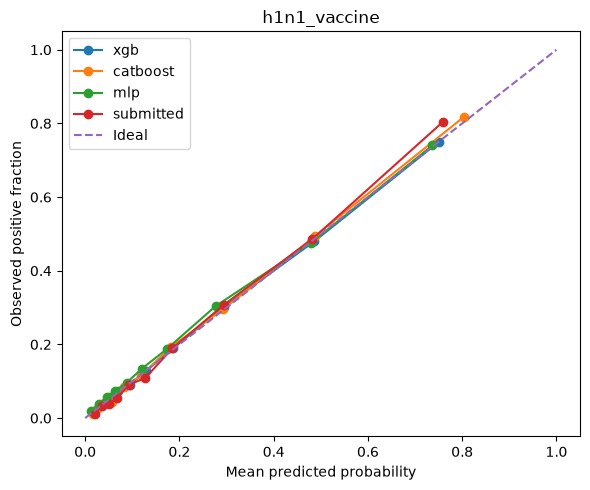

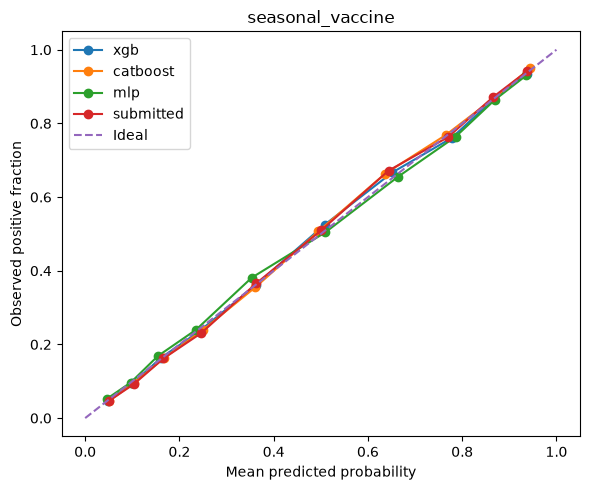


09_largest_oof_errors: 100 rows


,h1n1_vaccine,seasonal_vaccine,respondent_id,oof_log_loss,missing_count,p_h1n1,p_seasonal
16685,1,1,16685,4.129999,0,0.011531,0.022432
24816,1,1,24816,3.601766,2,0.019518,0.038115
12941,1,1,12941,3.522235,1,0.017394,0.050146
5861,1,1,5861,3.470329,3,0.039564,0.024457
11065,1,1,11065,3.446098,0,0.025837,0.039311
22679,1,1,22679,3.409343,1,0.025329,0.043158
17854,1,1,17854,3.393674,0,0.015182,0.074297
19217,1,1,19217,3.373076,1,0.017424,0.067457
15602,1,1,15602,3.285530,0,0.021892,0.063964
8585,0,0,8585,3.236330,1,0.966706,0.953592


Residual correlation is not a conditional-independence test. Large OOF errors and low subgroup AUC do not establish bad labels. Compare models within the same subgroup.


In [9]:
eda_metric_rows, eda_cross_label = [], []
for name, probability in eda_oof.items():
    residual = eda_y.to_numpy() - probability
    eda_cross_label.append({'model': name, 'label_residual_correlation': np.corrcoef(residual.T)[0, 1]})
    for j, target in enumerate(eda_targets):
        fold_auc = [roc_auc_score(eda_y.iloc[va, j], probability[va, j]) for _, va in eda_cv]
        eda_metric_rows.append({'model': name, 'target': target, 'mean_fold_auc': np.mean(fold_auc),
                                'pooled_oof_auc': roc_auc_score(eda_y[target], probability[:, j]),
                                'log_loss': log_loss(eda_y[target], probability[:, j], labels=[0, 1]),
                                'brier': np.mean(residual[:, j]**2)})
eda_report('09_oof_metrics', pd.DataFrame(eda_metric_rows), 10)
eda_report('09_cross_label_residuals', pd.DataFrame(eda_cross_label))
for j, target in enumerate(eda_targets):
    errors = pd.DataFrame({name: eda_y.iloc[:, j].to_numpy() - p[:, j] for name, p in eda_oof.items()})
    eda_report(f'09_model_error_correlation_{target}', errors.corr().rename_axis('model').reset_index())
eda_groups = {c: eda_levels(eda_X[c]) for c in [
    'age_group', 'health_insurance', 'employment_status', 'health_worker',
    'doctor_recc_h1n1', 'doctor_recc_seasonal',
] + eda_opinions if c in eda_X}
eda_groups['missing_count'] = eda_missing_bucket
eda_subgroup_rows = []
for feature, values in eda_groups.items():
    for level, idx in values.groupby(values, observed=True).groups.items():
        idx = np.asarray(idx)
        if len(idx) < EDA_MIN_GROUP:
            continue
        for j, target in enumerate(eda_targets):
            truth = eda_y.iloc[idx, j].to_numpy()
            if min(truth.sum(), len(truth) - truth.sum()) < 20:
                continue
            for name, probability in eda_oof.items():
                p = probability[idx, j]
                eda_subgroup_rows.append({'feature': feature, 'level': str(level), 'target': target,
                                          'model': name, 'n': len(idx), 'positive_rate': truth.mean(),
                                          'auc': roc_auc_score(truth, p), 'brier': np.mean((truth - p)**2),
                                          'prediction_bias': p.mean() - truth.mean()})
eda_subgroups = pd.DataFrame(eda_subgroup_rows)
eda_report('09_subgroup_metrics', eda_subgroups, 0)
if not eda_subgroups.empty:
    display(eda_subgroups.query('model == "submitted"').sort_values('auc').head(20).round(5))
eda_calibration = []
for name, probability in eda_oof.items():
    for j, target in enumerate(eda_targets):
        table = pd.DataFrame({'p': probability[:, j], 'y': eda_y[target]})
        table['bin'] = pd.qcut(table.p, 10, duplicates='drop')
        result = table.groupby('bin', observed=True).agg(n=('y', 'size'), predicted=('p', 'mean'), observed=('y', 'mean')).reset_index()
        result['bin'] = result['bin'].astype(str)
        eda_calibration.append(result.assign(model=name, target=target))
eda_report('09_calibration_bins', pd.concat(eda_calibration, ignore_index=True), 10)
for target in eda_targets:
    plt.figure(figsize=(6, 5))
    for name in eda_oof:
        plot = eda_tables['09_calibration_bins'].query('target == @target and model == @name')
        plt.plot(plot.predicted, plot.observed, marker='o', label=name)
    plt.plot([0, 1], [0, 1], linestyle='--', label='Ideal')
    plt.xlabel('Mean predicted probability')
    plt.ylabel('Observed positive fraction')
    plt.title(target)
    plt.legend()
    eda_save_figure(f'09_calibration_{target}')
p = np.clip(eda_oof['submitted'], 1e-6, 1 - 1e-6)
eda_row_loss = -(eda_y.to_numpy() * np.log(p) + (1 - eda_y.to_numpy()) * np.log(1 - p)).mean(axis=1)
eda_hard = eda_y.assign(respondent_id=eda_ids, oof_log_loss=eda_row_loss, missing_count=eda_missing_count,
                        p_h1n1=p[:, 0], p_seasonal=p[:, 1])
eda_report('09_largest_oof_errors', eda_hard.sort_values('oof_log_loss', ascending=False).head(100), 15)
eda_note('Residual correlation is not a conditional-independence test. Large OOF errors and low subgroup AUC do not establish bad labels. Compare models within the same subgroup.')


## 10) Unusual respondents

In [10]:
eda_anomaly_prep = eda_preprocessor(eda_X)
eda_anomaly_X = np.asarray(eda_anomaly_prep.fit_transform(eda_X), dtype=np.float32)
eda_anomaly_T = np.asarray(eda_anomaly_prep.transform(eda_T), dtype=np.float32)
eda_detector = IsolationForest(n_estimators=150, max_samples=min(512, len(eda_X)),
                               contamination='auto', random_state=EDA_SEED, n_jobs=min(EDA_THREADS, 4))
eda_detector.fit(eda_anomaly_X)
eda_anomaly_score = -eda_detector.score_samples(eda_anomaly_X)
eda_anomaly_test = -eda_detector.score_samples(eda_anomaly_T)
eda_anomaly_bucket = pd.qcut(pd.Series(eda_anomaly_score).rank(method='first'), [0, .95, .99, 1],
                             labels=['usual_95pct', 'unusual_4pct', 'most_unusual_1pct'])
eda_report('10_anomaly_group_rates', eda_rates(pd.DataFrame({'group': eda_anomaly_bucket})))
eda_anomaly_review = eda_hard.assign(anomaly_score=eda_anomaly_score)
eda_report('10_unusual_respondents', eda_anomaly_review.sort_values('anomaly_score', ascending=False).head(100), 15)
eda_anomaly_metrics = []
for level, idx in eda_anomaly_bucket.groupby(eda_anomaly_bucket, observed=True).groups.items():
    score = eda_auc2(eda_y.loc[idx], eda_oof['submitted'][idx])
    eda_anomaly_metrics.append({'group': str(level), 'n': len(idx), 'h1n1_auc': score[0], 'seasonal_auc': score[1],
                                'mean_oof_log_loss': eda_row_loss[idx].mean()})
eda_report('10_anomaly_error_profile', pd.DataFrame(eda_anomaly_metrics))
eda_note(f'Test fraction above the train 99th-percentile anomaly score: {(eda_anomaly_test > np.quantile(eda_anomaly_score, .99)).mean():.4f}')
eda_note('The most unusual 1% is a review budget, not an estimated error rate. No IQR filtering, label-based deletion or row removal is performed.')

eda_outlier_count_rows = []
for dataset, frame, anomaly in [('train', eda_X, eda_anomaly_score), ('test', eda_T, eda_anomaly_test)]:
    invalid = np.zeros(len(frame), dtype=bool)
    naive_iqr = np.zeros(len(frame), dtype=bool)
    for col, allowed in eda_allowed.items():
        invalid |= (frame[col].notna() & ~frame[col].isin(allowed)).to_numpy()
        q25, q75 = eda_X[col].quantile([.25, .75]).to_numpy()
        width = q75 - q25
        naive_iqr |= ((frame[col] < q25 - 1.5 * width) | (frame[col] > q75 + 1.5 * width)).to_numpy()
    rules = {
        'invalid_documented_response_code': invalid,
        'isolation_forest_auto_threshold': anomaly > -float(eda_detector.offset_),
        'above_train_anomaly_p99_review_only': anomaly > np.quantile(eda_anomaly_score, .99),
        'naive_numeric_iqr_not_a_deletion_rule': naive_iqr,
    }
    for rule, mask in rules.items():
        eda_outlier_count_rows.append({'dataset': dataset, 'rule': rule, 'n_flagged': int(mask.sum()),
                                       'fraction_flagged': float(mask.mean()),
                                       'flagged_with_valid_numeric_codes': int((mask & ~invalid).sum())})
eda_report('10_outlier_counts_by_definition', pd.DataFrame(eda_outlier_count_rows), 12)
eda_note('There is no ground-truth outlier count. Invalid survey codes, a model threshold, and a top-1% review rule answer different questions. The naive IQR count demonstrates how valid binary/ordinal answers can be mislabeled as outliers; no filtering is applied.')

del eda_anomaly_X, eda_anomaly_T, eda_detector



10_anomaly_group_rates: 3 rows


,group,n,h1n1_vaccine,h1n1_vaccine_lo,h1n1_vaccine_hi,seasonal_vaccine,seasonal_vaccine_lo,seasonal_vaccine_hi
0,usual_95pct,25371,0.210871,0.205895,0.215934,0.473020,0.466881,0.479168
1,unusual_4pct,1068,0.232210,0.207873,0.258466,0.335206,0.307529,0.364064
2,most_unusual_1pct,268,0.283582,0.232971,0.340310,0.283582,0.232971,0.340310



10_unusual_respondents: 100 rows


,h1n1_vaccine,seasonal_vaccine,respondent_id,oof_log_loss,missing_count,p_h1n1,p_seasonal,anomaly_score
4823,1,0,4823,0.589750,0,0.611162,0.496971,0.567875
3920,1,1,3920,0.567789,0,0.718090,0.447348,0.560284
15617,0,0,15617,0.195556,0,0.083687,0.261928,0.554300
12693,1,0,12693,0.451478,0,0.766068,0.470843,0.551996
25771,0,0,25771,0.067287,0,0.053007,0.076987,0.549988
1732,0,0,1732,0.581985,0,0.257524,0.579456,0.549917
23888,0,0,23888,0.125704,0,0.139793,0.095908,0.548778
18679,0,0,18679,0.417634,0,0.344041,0.338742,0.547971
26677,0,0,26677,0.833682,0,0.356181,0.706837,0.547723
7540,1,1,7540,0.857344,0,0.334049,0.538902,0.546828



10_anomaly_error_profile: 3 rows


,group,n,h1n1_auc,seasonal_auc,mean_oof_log_loss
0,usual_95pct,25371,0.866419,0.864910,0.402427
1,unusual_4pct,1068,0.828186,0.848340,0.424912
2,most_unusual_1pct,268,0.829770,0.821615,0.449079


Test fraction above the train 99th-percentile anomaly score: 0.0097
The most unusual 1% is a review budget, not an estimated error rate. No IQR filtering, label-based deletion or row removal is performed.

10_outlier_counts_by_definition: 8 rows


,dataset,rule,n_flagged,fraction_flagged,flagged_with_valid_numeric_codes
0,train,invalid_documented_response_code,0,0.000000,0
1,train,isolation_forest_auto_threshold,546,0.020444,546
2,train,above_train_anomaly_p99_review_only,268,0.010035,268
3,train,naive_numeric_iqr_not_a_deletion_rule,16801,0.629086,16801
4,test,invalid_documented_response_code,0,0.000000,0
5,test,isolation_forest_auto_threshold,530,0.019844,530
6,test,above_train_anomaly_p99_review_only,258,0.009660,258
7,test,naive_numeric_iqr_not_a_deletion_rule,16788,0.628576,16788


There is no ground-truth outlier count. Invalid survey codes, a model threshold, and a top-1% review rule answer different questions. The naive IQR count demonstrates how valid binary/ordinal answers can be mislabeled as outliers; no filtering is applied.


## 11) Fixed-parameter CatBoost diagnostic models

In [11]:
eda_cat_backend = 'CPU'
eda_benchmark_rows = []

def eda_cat_frame(frame):
    result = frame.copy()
    for c in result.select_dtypes(exclude='number').columns:
        result[c] = result[c].astype(object).where(result[c].notna(), '__MISSING__').astype(str)
    return result

def eda_cat_settings(iterations, categorical, backend):
    settings = dict(eda_params['catboost'])
    settings.update(iterations=int(iterations), loss_function='Logloss', eval_metric='Logloss',
                    task_type=backend, thread_count=EDA_THREADS, random_seed=EDA_SEED,
                    bootstrap_type='Bayesian', boosting_type='Plain', border_count=128,
                    allow_writing_files=False, cat_features=categorical, verbose=False)
    if backend == 'GPU':
        settings.update(devices='0', gpu_ram_part=.5)
    return settings

if EDA_RUN_MODEL_CHECKS and eda_cuda:
    tr, _ = eda_cv[0]
    bench_X = eda_cat_frame(eda_X.iloc[tr])
    for backend in ['CPU', 'GPU']:
        try:
            warm = CatBoostClassifier(**eda_cat_settings(8, eda_cat, backend))
            warm.fit(bench_X.iloc[:min(1000, len(bench_X))], eda_y.iloc[tr[:min(1000, len(tr))], 0])
            del warm
            started = perf_counter()
            bench = CatBoostClassifier(**eda_cat_settings(160, eda_cat, backend))
            bench.fit(bench_X, eda_y.iloc[tr, 0])
            elapsed = perf_counter() - started
            eda_benchmark_rows.append({'backend': backend, 'iterations': 160, 'seconds': elapsed, 'error': ''})
            print(f'CatBoost backend benchmark | {backend}: {elapsed:.2f}s', flush=True)
            del bench
        except Exception as error:
            eda_benchmark_rows.append({'backend': backend, 'iterations': 160, 'seconds': np.nan,
                                       'error': f'{type(error).__name__}: {error}'})
    successful = [r for r in eda_benchmark_rows if not r['error']]
    if not successful:
        raise RuntimeError('Neither CatBoost backend completed its benchmark. See eda_benchmark_rows.')
    eda_cat_backend = min(successful, key=lambda r: r['seconds'])['backend']
    del bench_X
elif EDA_RUN_MODEL_CHECKS:
    eda_note('CUDA was not detected; CatBoost diagnostics will use CPU.')
eda_report('11_backend_benchmark', pd.DataFrame(eda_benchmark_rows, columns=['backend', 'iterations', 'seconds', 'error']))
eda_note(f'CatBoost diagnostic backend: {eda_cat_backend}. The short benchmark estimates throughput, not model quality; CPU/GPU fits can differ.')

eda_cat_baselines, eda_training_ranks, eda_cat_reference = {}, {}, {}

def eda_fit_cat(frame, fold, variant, class_weight_power=0.):
    tr, _ = eda_cv[fold]
    prepared = eda_cat_frame(frame.iloc[tr])
    categorical = prepared.select_dtypes(exclude='number').columns.tolist()
    models = []
    for j, target in enumerate(eda_targets):
        settings = eda_cat_settings(eda_cat_counts[fold, j], categorical, eda_cat_backend)
        if class_weight_power != 0:
            positive = int(eda_y.iloc[tr, j].sum())
            negative = len(tr) - positive
            if min(positive, negative) == 0:
                raise ValueError('Both classes are required for class-weight checks.')
            settings['class_weights'] = [1., float((negative / positive)**class_weight_power)]
        descriptor = {'fingerprint': eda_fingerprint, 'version': eda_versions['catboost'], 'fold': fold,
                      'target': target, 'variant': variant, 'columns': frame.columns.tolist(), 'settings': settings,
                      'cv_seed': EDA_SEED, 'cv_n_splits': EDA_N_SPLITS, 'feature_code_version': 2,
                      'prepared_hash': hashlib.sha256(pd.util.hash_pandas_object(prepared, index=True).to_numpy().tobytes()).hexdigest()}
        key = hashlib.sha256(json.dumps(descriptor, sort_keys=True).encode()).hexdigest()[:24]
        path = eda_cache_dir / f'cat_{key}.cbm'
        started = perf_counter()
        cached = EDA_CACHE and path.is_file()
        if cached:
            model = CatBoostClassifier()
            model.load_model(str(path))
        else:
            print(f'{variant} | Fold {fold + 1}/{EDA_CHECK_FOLDS} | {target}: {settings["iterations"]} iterations on {eda_cat_backend}', flush=True)
            model = CatBoostClassifier(**settings)
            model.fit(prepared, eda_y.iloc[tr, j])
            if EDA_CACHE:
                model.save_model(str(path))
        elapsed = perf_counter() - started
        eda_timing.append({'stage': 'catboost', 'variant': variant, 'fold': fold + 1, 'target': target,
                           'seconds': elapsed, 'cached': cached})
        print(f'{variant} | Fold {fold + 1} | {target}: {elapsed:.1f}s' + (' (cached)' if cached else ''), flush=True)
        models.append(model)
    return models

def eda_cat_predict(models, frame):
    prepared = eda_cat_frame(frame)
    return np.column_stack([model.predict_proba(prepared, thread_count=EDA_THREADS)[:, 1] for model in models])

if EDA_RUN_MODEL_CHECKS:
    for fold, (_, va) in enumerate(eda_cv[:EDA_CHECK_FOLDS]):
        models = eda_fit_cat(eda_X, fold, 'all_features')
        eda_cat_baselines[fold] = models
        eda_training_ranks[fold] = pd.DataFrame(
            {t: models[j].get_feature_importance(type='PredictionValuesChange', thread_count=EDA_THREADS)
             for j, t in enumerate(eda_targets)}, index=eda_X.columns,
        )
        if not np.isfinite(eda_training_ranks[fold].to_numpy()).all():
            raise ValueError('CatBoost did not provide finite training feature importances.')
        eda_cat_reference[fold] = eda_auc2(eda_y.iloc[va], eda_cat_predict(models, eda_X.iloc[va]))
    eda_report('11_training_feature_ranks', pd.concat([
        ranks.rename_axis('feature').reset_index().assign(fold=fold + 1)
        for fold, ranks in eda_training_ranks.items()
    ], ignore_index=True), 10)
eda_note('Feature selection will use training-only rankings. All changes are compared with newly fitted same-backend baselines; no full-data model is scored on its own training rows.')


CatBoost backend benchmark | CPU: 5.02s
CatBoost backend benchmark | GPU: 2.19s

11_backend_benchmark: 2 rows


,backend,iterations,seconds,error
0,CPU,160,5.021053,
1,GPU,160,2.188396,


CatBoost diagnostic backend: GPU. The short benchmark estimates throughput, not model quality; CPU/GPU fits can differ.
all_features | Fold 1/3 | h1n1_vaccine: 1999 iterations on GPU
all_features | Fold 1 | h1n1_vaccine: 74.0s
all_features | Fold 1/3 | seasonal_vaccine: 1921 iterations on GPU
all_features | Fold 1 | seasonal_vaccine: 70.4s
all_features | Fold 2/3 | h1n1_vaccine: 2000 iterations on GPU
all_features | Fold 2 | h1n1_vaccine: 73.9s
all_features | Fold 2/3 | seasonal_vaccine: 1942 iterations on GPU
all_features | Fold 2 | seasonal_vaccine: 71.2s
all_features | Fold 3/3 | h1n1_vaccine: 1846 iterations on GPU
all_features | Fold 3 | h1n1_vaccine: 68.7s
all_features | Fold 3/3 | seasonal_vaccine: 1995 iterations on GPU
all_features | Fold 3 | seasonal_vaccine: 73.3s

11_training_feature_ranks: 105 rows


,feature,h1n1_vaccine,seasonal_vaccine,fold
0,h1n1_concern,2.203368,1.220428,1
1,h1n1_knowledge,1.665832,2.149804,1
2,behavioral_antiviral_meds,0.624521,0.296302,1
3,behavioral_avoidance,0.455920,0.225575,1
4,behavioral_face_mask,0.584944,0.142728,1
5,behavioral_wash_hands,0.366027,0.525461,1
6,behavioral_large_gatherings,0.680164,0.250149,1
7,behavioral_outside_home,0.528109,0.382149,1
8,behavioral_touch_face,0.299257,0.960026,1
9,doctor_recc_h1n1,15.972423,1.520916,1


Feature selection will use training-only rankings. All changes are compared with newly fitted same-backend baselines; no full-data model is scored on its own training rows.


## 12) Held-out raw and grouped permutation importance

Permutation importance | Fold 1: 10/43 feature/groups
Permutation importance | Fold 1: 20/43 feature/groups
Permutation importance | Fold 1: 30/43 feature/groups
Permutation importance | Fold 1: 40/43 feature/groups
Permutation importance | Fold 1: 3.0s
Permutation importance | Fold 2: 10/43 feature/groups
Permutation importance | Fold 2: 20/43 feature/groups
Permutation importance | Fold 2: 30/43 feature/groups
Permutation importance | Fold 2: 40/43 feature/groups
Permutation importance | Fold 2: 3.0s
Permutation importance | Fold 3: 10/43 feature/groups
Permutation importance | Fold 3: 20/43 feature/groups
Permutation importance | Fold 3: 30/43 feature/groups
Permutation importance | Fold 3: 40/43 feature/groups
Permutation importance | Fold 3: 3.0s

12_permutation_repeats: 258 rows

12_permutation_importance: 43 rows


,kind,feature,h1n1_drop,seasonal_drop,macro_drop,fold_std,positive_fold_share
41,group,perceived_risk,0.051562,0.074020,0.062791,0.001843,1.000000
36,group,doctor_recommendations,0.065947,0.041548,0.053747,0.001397,1.000000
11,feature,doctor_recc_h1n1,0.080955,0.001054,0.041004,0.002053,1.000000
37,group,effectiveness,0.029771,0.044764,0.037267,0.004357,1.000000
29,feature,opinion_seas_risk,0.005590,0.063278,0.034434,0.002888,1.000000
19,feature,health_insurance,0.059178,0.007066,0.033122,0.003185,1.000000
12,feature,doctor_recc_seasonal,0.005268,0.046288,0.025778,0.000796,1.000000
31,feature,opinion_seas_vacc_effective,0.000591,0.044375,0.022483,0.004494,1.000000
0,feature,age_group,0.003058,0.037500,0.020279,0.001550,1.000000
26,feature,opinion_h1n1_risk,0.031371,0.002202,0.016787,0.001092,1.000000


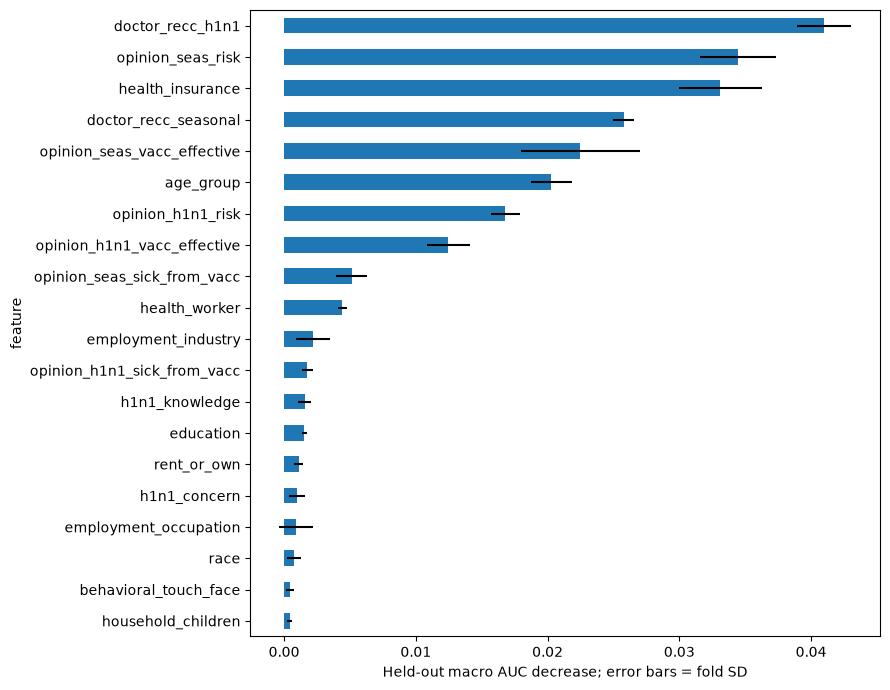

A positive drop means useful information for this CatBoost model. Near-zero/negative values are not automatic removal rules. Correlated features may substitute for one another; groups are shuffled jointly.


In [12]:
eda_blocks = {
    'doctor_recommendations': ['doctor_recc_h1n1', 'doctor_recc_seasonal'],
    'effectiveness': ['opinion_h1n1_vacc_effective', 'opinion_seas_vacc_effective'],
    'perceived_risk': ['opinion_h1n1_risk', 'opinion_seas_risk'],
    'vaccine_worry': ['opinion_h1n1_sick_from_vacc', 'opinion_seas_sick_from_vacc'],
    'behaviors': [c for c in eda_X if c.startswith('behavioral_')],
    'employment': ['employment_status', 'employment_industry', 'employment_occupation'],
    'geography': ['hhs_geo_region', 'census_msa'],
    'household': ['household_adults', 'household_children'],
}
eda_blocks = {name: [c for c in cols if c in eda_X] for name, cols in eda_blocks.items()}
eda_units = [('feature', c, [c]) for c in eda_X] + [('group', name, cols) for name, cols in eda_blocks.items() if cols]
eda_pfi_rows = []
if EDA_RUN_MODEL_CHECKS:
    for fold, (_, va) in enumerate(eda_cv[:EDA_CHECK_FOLDS]):
        started = perf_counter()
        rng = np.random.default_rng(EDA_SEED + fold)
        idx = rng.choice(va, size=min(EDA_PFI_ROWS, len(va)), replace=False)
        if (eda_y.iloc[idx].nunique() != 2).any():
            idx = va
        valid, truth = eda_X.iloc[idx].copy(), eda_y.iloc[idx]
        models = eda_cat_baselines[fold]
        reference = eda_auc2(truth, eda_cat_predict(models, valid))
        permutations = [rng.permutation(len(valid)) for _ in range(EDA_PFI_REPEATS)]
        for unit, (kind, name, cols) in enumerate(eda_units):
            for repeat, order in enumerate(permutations):
                shuffled = valid.copy()
                for c in cols:
                    shuffled[c] = valid[c].to_numpy()[order]
                drop = reference - eda_auc2(truth, eda_cat_predict(models, shuffled))
                eda_pfi_rows.append({'fold': fold + 1, 'repeat': repeat + 1, 'kind': kind, 'feature': name,
                                     'h1n1_drop': drop[0], 'seasonal_drop': drop[1], 'macro_drop': drop.mean()})
            if (unit + 1) % 10 == 0:
                print(f'Permutation importance | Fold {fold + 1}: {unit + 1}/{len(eda_units)} feature/groups', flush=True)
        print(f'Permutation importance | Fold {fold + 1}: {perf_counter() - started:.1f}s', flush=True)
    eda_pfi_raw = pd.DataFrame(eda_pfi_rows)
    eda_report('12_permutation_repeats', eda_pfi_raw, 0)
    by_fold = eda_pfi_raw.groupby(['kind', 'feature', 'fold'])[['h1n1_drop', 'seasonal_drop', 'macro_drop']].mean().reset_index()
    eda_pfi = by_fold.groupby(['kind', 'feature']).agg(
        h1n1_drop=('h1n1_drop', 'mean'), seasonal_drop=('seasonal_drop', 'mean'),
        macro_drop=('macro_drop', 'mean'), fold_std=('macro_drop', 'std'),
        positive_fold_share=('macro_drop', lambda s: s.gt(0).mean()),
    ).reset_index().sort_values('macro_drop', ascending=False)
    eda_report('12_permutation_importance', eda_pfi, 25)
    eda_pfi_plot = eda_pfi.query('kind == "feature"').head(20).iloc[::-1].copy()
    eda_pfi_plot['fold_std'] = eda_pfi_plot['fold_std'].fillna(0)
    eda_pfi_plot.plot.barh(
        x='feature', y='macro_drop', xerr='fold_std', figsize=(9, 7), legend=False,
    )
    plt.xlabel('Held-out macro AUC decrease; error bars = fold SD')
    eda_save_figure('12_permutation_importance')
    eda_note('A positive drop means useful information for this CatBoost model. Near-zero/negative values are not automatic removal rules. Correlated features may substitute for one another; groups are shuffled jointly.')


## 13) Controlled feature-selection experiments

In [13]:
eda_selection_rows = []
if EDA_RUN_MODEL_CHECKS:
    for fold, (_, va) in enumerate(eda_cv[:EDA_CHECK_FOLDS]):
        ranking = eda_training_ranks[fold].mean(axis=1).sort_values(ascending=False)
        for count in [25, 15]:
            keep = ranking.head(min(count, len(ranking))).index.tolist()
            models = eda_fit_cat(eda_X[keep], fold, f'top_{count}')
            score = eda_auc2(eda_y.iloc[va], eda_cat_predict(models, eda_X.iloc[va][keep]))
            delta = score - eda_cat_reference[fold]
            eda_selection_rows.append({'fold': fold + 1, 'n_features': len(keep), 'macro_auc': score.mean(),
                                        'delta_macro': delta.mean(), 'delta_h1n1': delta[0], 'delta_seasonal': delta[1],
                                        'selected_features': '|'.join(keep)})
            del models
    eda_feature_selection = pd.DataFrame(eda_selection_rows)
    eda_report('13_feature_selection_folds', eda_feature_selection)
    eda_report('13_feature_selection_summary', eda_feature_selection.groupby('n_features').agg(
        macro_auc=('macro_auc', 'mean'), delta_macro=('delta_macro', 'mean'),
        delta_h1n1=('delta_h1n1', 'mean'), delta_seasonal=('delta_seasonal', 'mean'),
        delta_fold_std=('delta_macro', 'std'), improved_folds=('delta_macro', lambda s: s.gt(0).sum()),
    ).reset_index())
    eda_note('Each shortlist is chosen using only that fold\'s training labels, not the held-out permutation ranking. Hyperparameters/iteration counts are fixed; confirm candidates on all five folds before changing main.ipynb.')


top_25 | Fold 1/3 | h1n1_vaccine: 1999 iterations on GPU
top_25 | Fold 1 | h1n1_vaccine: 71.8s
top_25 | Fold 1/3 | seasonal_vaccine: 1921 iterations on GPU
top_25 | Fold 1 | seasonal_vaccine: 68.4s
top_15 | Fold 1/3 | h1n1_vaccine: 1999 iterations on GPU
top_15 | Fold 1 | h1n1_vaccine: 45.9s
top_15 | Fold 1/3 | seasonal_vaccine: 1921 iterations on GPU
top_15 | Fold 1 | seasonal_vaccine: 44.5s
top_25 | Fold 2/3 | h1n1_vaccine: 2000 iterations on GPU
top_25 | Fold 2 | h1n1_vaccine: 75.0s
top_25 | Fold 2/3 | seasonal_vaccine: 1942 iterations on GPU
top_25 | Fold 2 | seasonal_vaccine: 71.1s
top_15 | Fold 2/3 | h1n1_vaccine: 2000 iterations on GPU
top_15 | Fold 2 | h1n1_vaccine: 47.4s
top_15 | Fold 2/3 | seasonal_vaccine: 1942 iterations on GPU
top_15 | Fold 2 | seasonal_vaccine: 46.0s
top_25 | Fold 3/3 | h1n1_vaccine: 1846 iterations on GPU
top_25 | Fold 3 | h1n1_vaccine: 69.0s
top_25 | Fold 3/3 | seasonal_vaccine: 1995 iterations on GPU
top_25 | Fold 3 | seasonal_vaccine: 74.1s
top_15 | F

,fold,n_features,macro_auc,delta_macro,delta_h1n1,delta_seasonal,selected_features
0,1,25,0.869607,-0.000673,-0.000682,-0.000664,opinion_seas_risk|health_insurance|doctor_recc...
1,1,15,0.868086,-0.002194,-0.002145,-0.002243,opinion_seas_risk|health_insurance|doctor_recc...
2,2,25,0.866761,-0.000344,-0.000521,-0.000167,opinion_seas_risk|health_insurance|doctor_recc...
3,2,15,0.864890,-0.002215,-0.001941,-0.002490,opinion_seas_risk|health_insurance|doctor_recc...
4,3,25,0.868555,-0.000422,-0.001024,0.000179,opinion_seas_risk|health_insurance|doctor_recc...
5,3,15,0.866493,-0.002485,-0.003667,-0.001303,opinion_seas_risk|health_insurance|doctor_recc...



13_feature_selection_summary: 2 rows


,n_features,macro_auc,delta_macro,delta_h1n1,delta_seasonal,delta_fold_std,improved_folds
0,15,0.866490,-0.002298,-0.002584,-0.002012,0.000162,0
1,25,0.868308,-0.000480,-0.000742,-0.000217,0.000172,0


Each shortlist is chosen using only that fold's training labels, not the held-out permutation ranking. Hyperparameters/iteration counts are fixed; confirm candidates on all five folds before changing main.ipynb.


## 14) Missingness, opinion encoding and paired-vaccine features

In [14]:
def eda_representation(frame, mode):
    result = frame.copy()
    if mode in ['missing_flags', 'missing_and_known_opinions']:
        result = pd.concat([result, frame.isna().astype(np.int8).add_suffix('__missing')], axis=1)
    if mode == 'opinions_nominal':
        for c in eda_opinions:
            result[c] = eda_levels(frame[c]).astype(object).where(frame[c].notna(), np.nan)
    if mode in ['opinions_known_scale', 'missing_and_known_opinions']:
        for c in eda_opinions:
            result[f'{c}__unknown'] = frame[c].eq(3).astype(np.int8)
            result[f'{c}__missing'] = frame[c].isna().astype(np.int8)
            result[c] = frame[c].map({1: 0., 2: 1., 4: 2., 5: 3.})
    if mode == 'paired_vaccine_features':
        for stem, a, b in [
            ('effectiveness', 'opinion_h1n1_vacc_effective', 'opinion_seas_vacc_effective'),
            ('risk', 'opinion_h1n1_risk', 'opinion_seas_risk'),
            ('worry', 'opinion_h1n1_sick_from_vacc', 'opinion_seas_sick_from_vacc'),
        ]:
            if a in frame and b in frame:
                left, right = [frame[c].map({1: 0., 2: 1., 4: 2., 5: 3.}) for c in [a, b]]
                result[f'pair_{stem}_difference'] = left - right
                result[f'pair_{stem}_sum'] = left + right
                result[f'pair_{stem}_both_known'] = (left.notna() & right.notna()).astype(np.int8)
        if {'doctor_recc_h1n1', 'doctor_recc_seasonal'}.issubset(frame.columns):
            result['doctor_recommendation_pattern'] = (eda_levels(frame.doctor_recc_h1n1) + '|' + eda_levels(frame.doctor_recc_seasonal)).astype(object)
    return result

eda_encoding_rows = []
if EDA_RUN_MODEL_CHECKS:
    for mode in ['original', 'missing_flags', 'opinions_nominal', 'opinions_known_scale',
                 'missing_and_known_opinions', 'paired_vaccine_features']:
        frame = eda_representation(eda_X, mode)
        for fold, (tr, va) in enumerate(eda_cv[:EDA_CHECK_FOLDS]):
            descriptor = {'fingerprint': eda_fingerprint, 'version': eda_versions['xgboost'],
                          'mode': mode, 'representation_version': 1, 'fold': fold, 'seed': EDA_SEED, 'n_splits': EDA_N_SPLITS,
                          'params': eda_params['xgb'], 'device': eda_xgb_device}
            key = hashlib.sha256(json.dumps(descriptor, sort_keys=True).encode()).hexdigest()[:24]
            path = eda_cache_dir / f'xgb_{key}.npz'
            started = perf_counter()
            cached = EDA_CACHE and path.is_file()
            print(f'XGBoost representation check | {mode} | Fold {fold + 1}/{EDA_CHECK_FOLDS}', flush=True)
            if cached:
                with np.load(path, allow_pickle=False) as saved:
                    probability = saved['probability']
            else:
                transformer = eda_preprocessor(frame)
                fit_X = np.asarray(transformer.fit_transform(frame.iloc[tr]), dtype=np.float32)
                valid_X = np.asarray(transformer.transform(frame.iloc[va]), dtype=np.float32)
                model = XGBClassifier(**eda_params['xgb'], objective='binary:logistic', tree_method='hist',
                                      device=eda_xgb_device, n_jobs=EDA_THREADS, random_state=EDA_SEED)
                model.fit(fit_X, eda_y.iloc[tr])
                model.set_params(device='cpu')
                probability = model.predict_proba(valid_X)
                if EDA_CACHE:
                    np.savez_compressed(path, probability=probability)
                del model, transformer, fit_X, valid_X
            score = eda_auc2(eda_y.iloc[va], probability)
            elapsed = perf_counter() - started
            eda_encoding_rows.append({'mode': mode, 'fold': fold + 1, 'h1n1_auc': score[0],
                                       'seasonal_auc': score[1], 'macro_auc': score.mean(), 'seconds': elapsed})
            eda_timing.append({'stage': 'xgboost', 'variant': mode, 'fold': fold + 1, 'target': 'both',
                               'seconds': elapsed, 'cached': cached})
            print(f'{mode} | Fold {fold + 1}: AUC={score.mean():.6f} | {elapsed:.1f}s' + (' (cached)' if cached else ''), flush=True)
    eda_encoding = pd.DataFrame(eda_encoding_rows)
    reference = eda_encoding.query('mode == "original"').set_index('fold')
    for col in ['macro_auc', 'h1n1_auc', 'seasonal_auc']:
        eda_encoding[f'delta_{col}'] = eda_encoding[col] - eda_encoding.fold.map(reference[col])
    eda_report('14_encoding_folds', eda_encoding, 10)
    eda_report('14_encoding_summary', eda_encoding.groupby('mode').agg(
        macro_auc=('macro_auc', 'mean'), delta_macro=('delta_macro_auc', 'mean'),
        delta_h1n1=('delta_h1n1_auc', 'mean'), delta_seasonal=('delta_seasonal_auc', 'mean'),
        delta_fold_std=('delta_macro_auc', 'std'), improved_folds=('delta_macro_auc', lambda s: s.gt(0).sum()),
    ).reset_index().sort_values('macro_auc', ascending=False))
    eda_note('Opinion coding and feature constructions are hypotheses, not presumed improvements. These fixed-XGBoost screens do not establish what will help the MLP. No true target is used as a feature.')


XGBoost representation check | original | Fold 1/3
original | Fold 1: AUC=0.851914 | 4.6s
XGBoost representation check | original | Fold 2/3
original | Fold 2: AUC=0.849849 | 4.5s
XGBoost representation check | original | Fold 3/3
original | Fold 3: AUC=0.852300 | 4.5s
XGBoost representation check | missing_flags | Fold 1/3
missing_flags | Fold 1: AUC=0.869816 | 4.6s
XGBoost representation check | missing_flags | Fold 2/3
missing_flags | Fold 2: AUC=0.866588 | 4.6s
XGBoost representation check | missing_flags | Fold 3/3
missing_flags | Fold 3: AUC=0.867560 | 4.6s
XGBoost representation check | opinions_nominal | Fold 1/3
opinions_nominal | Fold 1: AUC=0.851594 | 4.6s
XGBoost representation check | opinions_nominal | Fold 2/3
opinions_nominal | Fold 2: AUC=0.849332 | 4.5s
XGBoost representation check | opinions_nominal | Fold 3/3
opinions_nominal | Fold 3: AUC=0.853125 | 4.6s
XGBoost representation check | opinions_known_scale | Fold 1/3
opinions_known_scale | Fold 1: AUC=0.851802 | 4.6

,mode,fold,h1n1_auc,seasonal_auc,macro_auc,seconds,delta_macro_auc,delta_h1n1_auc,delta_seasonal_auc
0,original,1,0.839731,0.864097,0.851914,4.622042,0.000000,0.000000,0.000000
1,original,2,0.835245,0.864452,0.849849,4.500038,0.000000,0.000000,0.000000
2,original,3,0.845568,0.859033,0.852300,4.489426,0.000000,0.000000,0.000000
3,missing_flags,1,0.872347,0.867284,0.869816,4.577229,0.017902,0.032616,0.003188
4,missing_flags,2,0.866343,0.866832,0.866588,4.587122,0.016739,0.031098,0.002380
5,missing_flags,3,0.870863,0.864256,0.867560,4.594701,0.015259,0.025295,0.005223
6,opinions_nominal,1,0.840221,0.862966,0.851594,4.590865,-0.000320,0.000490,-0.001130
7,opinions_nominal,2,0.834684,0.863980,0.849332,4.549999,-0.000517,-0.000562,-0.000472
8,opinions_nominal,3,0.847320,0.858930,0.853125,4.553449,0.000825,0.001752,-0.000103
9,opinions_known_scale,1,0.839631,0.863973,0.851802,4.563531,-0.000112,-0.000100,-0.000123



14_encoding_summary: 6 rows


,mode,macro_auc,delta_macro,delta_h1n1,delta_seasonal,delta_fold_std,improved_folds
1,missing_flags,0.867988,0.016633,0.029670,0.003597,0.001325,3
0,missing_and_known_opinions,0.867888,0.016534,0.029652,0.003416,0.001334,3
5,paired_vaccine_features,0.854463,0.003108,0.004320,0.001897,0.001152,3
2,opinions_known_scale,0.851515,0.000161,0.000415,-0.000094,0.000703,1
4,original,0.851354,0.000000,0.000000,0.000000,0.000000,0
3,opinions_nominal,0.851350,-0.000004,0.000560,-0.000568,0.000724,1


Opinion coding and feature constructions are hypotheses, not presumed improvements. These fixed-XGBoost screens do not establish what will help the MLP. No true target is used as a feature.


## 15) Employment-related missingness

In [15]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.preprocessing import MaxAbsScaler, RobustScaler

eda_extra_revision = 2
eda_extra_prep_meta = []
eda_extra_fit_meta = []
eda_numeric = eda_X.select_dtypes('number').columns.tolist()
eda_employment_fields = [c for c in ['employment_industry', 'employment_occupation'] if c in eda_X]


def eda_employment_context(frame):
    result = frame.copy()
    if 'employment_status' not in frame:
        return result
    status = frame['employment_status'].astype('string').str.strip().str.casefold()
    tags = pd.Series('__MISSING__OTHER_OR_UNKNOWN_STATUS', index=frame.index, dtype=object)
    for value, tag in {
        'not in labor force': '__MISSING__NOT_IN_LABOR_FORCE',
        'unemployed': '__MISSING__UNEMPLOYED',
        'employed': '__MISSING__EMPLOYED',
    }.items():
        tags.loc[status.eq(value).fillna(False)] = tag
    for col in eda_employment_fields:
        observed = frame[col].notna()
        result[col] = frame[col].astype(object)
        result.loc[~observed, col] = tags.loc[~observed]
        if not result.loc[observed, col].equals(frame.loc[observed, col].astype(object)):
            raise AssertionError('Employment encoding must not replace an observed answer.')
    return result


def eda_extra_key(kind, descriptor):
    payload = {
        'revision': eda_extra_revision, 'kind': kind,
        'fingerprint': eda_fingerprint, 'versions': eda_versions,
        'seed': EDA_SEED, 'n_splits': EDA_N_SPLITS, **descriptor,
    }
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()[:24]


def eda_extra_prepared(fold, categorical='mode', numeric='median', scaler='standard',
                       flags=False, opinion_coding='raw'):
    spec = dict(fold=fold, categorical=categorical, numeric=numeric, scaler=scaler,
                flags=flags, opinion_coding=opinion_coding,
                knn_donors=EDA_KNN_MAX_DONORS, knn_neighbors=EDA_KNN_NEIGHBORS,
                iterative_rounds=EDA_IMPUTER_MAX_ITER)
    path = eda_cache_dir / f'prep_{eda_extra_key("preprocessing", spec)}.npz'
    started = perf_counter()
    if EDA_CACHE and path.is_file():
        with np.load(path, allow_pickle=False) as saved:
            fit_X, valid_X = saved['fit_X'], saved['valid_X']
            metadata = json.loads(str(saved['metadata'].item()))
        eda_extra_prep_meta.append(dict(metadata, cached=True, load_seconds=perf_counter() - started))
        return fit_X, valid_X, metadata

    tr, va = eda_cv[fold]
    frames = [eda_X.iloc[idx].copy() for idx in [tr, va]]
    if categorical == 'employment_context':
        frames = [eda_employment_context(frame) for frame in frames]
    elif categorical not in ['mode', 'missing']:
        raise ValueError(f'Unknown categorical strategy: {categorical}')

    flag_frames = [pd.DataFrame(index=frame.index) for frame in frames]
    if flags:
        flag_frames = [frame[eda_numeric].isna().astype(np.float32).add_suffix('__missing') for frame in frames]
    if opinion_coding == 'known':
        for frame, flag_frame in zip(frames, flag_frames):
            for col in eda_opinions:
                flag_frame[f'{col}__unknown'] = frame[col].eq(3).astype(np.float32)
                flag_frame[f'{col}__missing'] = frame[col].isna().astype(np.float32)
                frame[col] = frame[col].map({1: 0., 2: 1., 4: 2., 5: 3.})
    elif opinion_coding != 'raw':
        raise ValueError(f'Unknown opinion coding: {opinion_coding}')

    raw_fit, raw_valid = [frame[eda_numeric].to_numpy(dtype=float) for frame in frames]
    if np.isinf(raw_fit).any() or np.isinf(raw_valid).any():
        raise ValueError('Numeric input contains infinity; inspect the response-code audit.')
    donor_count = len(tr)
    n_imputer_iter = 0
    imputer_warnings = []
    if numeric == 'native':
        fit_num, valid_num = raw_fit.copy(), raw_valid.copy()
    elif numeric == 'median':
        imputer = SimpleImputer(strategy='median', keep_empty_features=True)
        fit_num = imputer.fit_transform(raw_fit)
        valid_num = imputer.transform(raw_valid)
    elif numeric in ['knn', 'iterative']:
        lower, upper = [], []
        for j, col in enumerate(eda_numeric):
            known_bounds = [0, 3] if opinion_coding == 'known' and col in eda_opinions else eda_allowed.get(col)
            observed = raw_fit[:, j][np.isfinite(raw_fit[:, j])]
            lo = float(min(known_bounds)) if known_bounds else float(observed.min()) if len(observed) else 0.
            hi = float(max(known_bounds)) if known_bounds else float(observed.max()) if len(observed) else 1.
            lower.append(lo)
            upper.append(hi if hi > lo else lo + 1.)
        lower, upper = np.asarray(lower), np.asarray(upper)
        width = upper - lower
        normalized_fit = (raw_fit - lower) / width
        normalized_valid = (raw_valid - lower) / width
        if numeric == 'knn':
            donor_count = min(EDA_KNN_MAX_DONORS, len(tr)) if EDA_KNN_MAX_DONORS else len(tr)
            donors = np.random.default_rng(EDA_SEED + fold).choice(len(tr), donor_count, replace=False)
            imputer = KNNImputer(n_neighbors=min(EDA_KNN_NEIGHBORS, donor_count), weights='distance',
                                 keep_empty_features=True)
            imputer.fit(normalized_fit[donors])
            with threadpool_limits(limits=min(EDA_THREADS, 4)):
                filled_fit = imputer.transform(normalized_fit)
                filled_valid = imputer.transform(normalized_valid)
        else:
            imputer = IterativeImputer(max_iter=EDA_IMPUTER_MAX_ITER, initial_strategy='median',
                                      min_value=0., max_value=1., random_state=EDA_SEED + fold,
                                      skip_complete=True, keep_empty_features=True)
            import warnings
            with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=min(EDA_THREADS, 4)):
                warnings.simplefilter('always')
                filled_fit = imputer.fit_transform(normalized_fit)
                filled_valid = imputer.transform(normalized_valid)
            imputer_warnings = sorted(set(str(w.message) for w in caught))
            n_imputer_iter = int(imputer.n_iter_)
            for message in imputer_warnings:
                print(f'IterativeImputer | Fold {fold + 1}: {message}', flush=True)
        fit_num = np.clip(filled_fit, 0, 1) * width + lower
        valid_num = np.clip(filled_valid, 0, 1) * width + lower
        fit_num[~np.isnan(raw_fit)] = raw_fit[~np.isnan(raw_fit)]
        valid_num[~np.isnan(raw_valid)] = raw_valid[~np.isnan(raw_valid)]
    else:
        raise ValueError(f'Unknown numeric imputation: {numeric}')

    missing_valid = np.isnan(raw_valid)
    estimated = valid_num[missing_valid]
    finite_estimated = estimated[np.isfinite(estimated)]
    fraction_fractional = (float((np.abs(finite_estimated - np.rint(finite_estimated)) > 1e-6).mean())
                           if len(finite_estimated) else np.nan)
    scales = {'standard': StandardScaler, 'maxabs': MaxAbsScaler, 'robust': RobustScaler}
    if scaler in scales:
        transform = scales[scaler]()
        fit_num = transform.fit_transform(fit_num)
        valid_num = transform.transform(valid_num)
    elif scaler == 'standard_nonbinary':
        binary = [i for i, col in enumerate(eda_numeric) if eda_allowed.get(col) == [0, 1]]
        other = [i for i in range(len(eda_numeric)) if i not in binary]
        if other:
            transform = StandardScaler()
            fit_num[:, other] = transform.fit_transform(fit_num[:, other])
            valid_num[:, other] = transform.transform(valid_num[:, other])
    elif scaler != 'none':
        raise ValueError(f'Unknown scaler: {scaler}')

    if eda_cat:
        if categorical == 'mode':
            cat_transform = make_pipeline(
                SimpleImputer(strategy='most_frequent', keep_empty_features=True),
                OneHotEncoder(handle_unknown='ignore', sparse_output=False),
            )
        else:
            cat_transform = make_pipeline(
                SimpleImputer(strategy='constant', fill_value='__MISSING__', keep_empty_features=True),
                OneHotEncoder(handle_unknown='ignore', sparse_output=False),
            )
        fit_cat = cat_transform.fit_transform(frames[0][eda_cat].astype(object))
        valid_cat = cat_transform.transform(frames[1][eda_cat].astype(object))
    else:
        fit_cat, valid_cat = np.empty((len(tr), 0)), np.empty((len(va), 0))
    fit_X = np.ascontiguousarray(np.column_stack([fit_num, fit_cat, flag_frames[0].to_numpy()]), dtype=np.float32)
    valid_X = np.ascontiguousarray(np.column_stack([valid_num, valid_cat, flag_frames[1].to_numpy()]), dtype=np.float32)
    if numeric != 'native' and (not np.isfinite(fit_X).all() or not np.isfinite(valid_X).all()):
        raise ValueError('The preprocessing experiment produced non-finite values.')
    metadata = dict(spec, donor_count=int(donor_count), iterative_rounds_used=n_imputer_iter,
                    imputer_warnings=imputer_warnings, n_features=fit_X.shape[1],
                    validation_numeric_missing=int(missing_valid.sum()),
                    fraction_fractional_imputed=fraction_fractional, seconds=perf_counter() - started)
    if EDA_CACHE:
        np.savez_compressed(path, fit_X=fit_X, valid_X=valid_X, metadata=np.array(json.dumps(metadata)))
    eda_extra_prep_meta.append(dict(metadata, cached=False))
    return fit_X, valid_X, metadata


def eda_mlp_epochs(fold):
    raw = eda_best_trials['mlp'].get('user_attrs_best_epochs')
    if isinstance(raw, str):
        epochs = int(eda_parse_list(raw)[fold])
    else:
        path = EDA_ROOT / 'mlp_refit_epochs.json'
        if not path.is_file():
            raise FileNotFoundError('MLP diagnostic needs saved per-fold best_epochs or mlp_refit_epochs.json.')
        epochs = int(eda_json(path)['epochs'])
    if EDA_MLP_EPOCH_CAP is not None:
        epochs = min(epochs, EDA_MLP_EPOCH_CAP)
    return max(1, epochs)


def eda_extra_predict(kind, fold, prep_spec=None, weight_power=0.):
    prep_spec = dict(prep_spec or {})
    tr, va = eda_cv[fold]
    positive = eda_y.iloc[tr].sum().to_numpy(dtype=float)
    negative = len(tr) - positive
    if (positive == 0).any() or (negative == 0).any():
        raise ValueError('Both classes are required in each training fold.')
    pos_weights = (negative / positive)**weight_power
    epochs = eda_mlp_epochs(fold) if kind == 'mlp' else None
    descriptor = dict(fold=fold, model=kind, prep_spec=prep_spec, weight_power=weight_power,
                      params=eda_params['mlp' if kind == 'mlp' else 'xgb'],
                      device=eda_xgb_device, epochs=epochs,
                      knn_donors=EDA_KNN_MAX_DONORS, knn_neighbors=EDA_KNN_NEIGHBORS,
                      iterative_rounds=EDA_IMPUTER_MAX_ITER,
                      torch_version=str(torch.__version__) if kind == 'mlp' else None)
    path = eda_cache_dir / f'prediction_{eda_extra_key("fixed_fit", descriptor)}.npz'
    started = perf_counter()
    cached = EDA_CACHE and path.is_file()
    if cached:
        with np.load(path, allow_pickle=False) as saved:
            probability = saved['probability']
            metadata = json.loads(str(saved['metadata'].item()))
    else:
        fit_X, valid_X, preprocessing = eda_extra_prepared(fold, **prep_spec)
        print(f'{kind} | Fold {fold + 1}/{EDA_CHECK_FOLDS} | {prep_spec} | positive weights={pos_weights.round(3).tolist()}', flush=True)
        last_loss = None
        if kind in ['xgb', 'xgb_separate']:
            settings = dict(eda_params['xgb'])
            settings.update(objective='binary:logistic', tree_method='hist', device=eda_xgb_device,
                            n_jobs=EDA_THREADS, random_state=EDA_SEED)
            if kind == 'xgb':
                if weight_power != 0:
                    raise ValueError('Use separate XGBoost estimators for target-specific class weights.')
                model = XGBClassifier(**settings)
                model.fit(fit_X, eda_y.iloc[tr])
                model.set_params(device='cpu')
                probability = model.predict_proba(valid_X)
                del model
            else:
                pieces = []
                for j in range(2):
                    model = XGBClassifier(**dict(settings, scale_pos_weight=float(pos_weights[j])))
                    model.fit(fit_X, eda_y.iloc[tr, j])
                    model.set_params(device='cpu')
                    pieces.append(model.predict_proba(valid_X)[:, 1])
                    del model
                probability = np.column_stack(pieces)
        elif kind == 'mlp':
            if not np.isfinite(fit_X).all() or not np.isfinite(valid_X).all():
                raise ValueError('The MLP requires finite inputs.')
            torch.manual_seed(EDA_SEED + fold)
            if eda_cuda:
                torch.cuda.manual_seed_all(EDA_SEED + fold)
            torch.set_num_threads(min(EDA_THREADS, 4))
            params = eda_params['mlp']
            hidden1, hidden2 = [int(value) for value in params['architecture'].split('_')]
            model = torch.nn.Sequential(
                torch.nn.Linear(fit_X.shape[1], hidden1), torch.nn.ReLU(), torch.nn.Dropout(params['dropout']),
                torch.nn.Linear(hidden1, hidden2), torch.nn.ReLU(), torch.nn.Dropout(params['dropout']),
                torch.nn.Linear(hidden2, 2),
            ).to(eda_xgb_device)
            fit_tensor = torch.as_tensor(fit_X, device=eda_xgb_device)
            truth_tensor = torch.as_tensor(eda_y.iloc[tr].to_numpy(dtype=np.float32), device=eda_xgb_device)
            loss_fn = torch.nn.BCEWithLogitsLoss(
                pos_weight=torch.tensor(pos_weights, dtype=torch.float32, device=eda_xgb_device)
            )
            optimizer = torch.optim.AdamW(model.parameters(), lr=params['learning_rate'], weight_decay=params['weight_decay'])
            for epoch in range(1, epochs + 1):
                model.train()
                order = torch.randperm(len(tr), device=eda_xgb_device)
                total_loss = torch.zeros((), device=eda_xgb_device)
                for idx in order.split(int(params['batch_size'])):
                    optimizer.zero_grad(set_to_none=True)
                    loss = loss_fn(model(fit_tensor[idx]), truth_tensor[idx])
                    loss.backward()
                    optimizer.step()
                    total_loss += loss.detach() * len(idx)
                last_loss = float((total_loss / len(tr)).item())
                if not np.isfinite(last_loss):
                    raise FloatingPointError('Non-finite MLP training loss.')
                if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
                    print(f'MLP | Epoch {epoch}/{epochs} | training BCE={last_loss:.6f}', flush=True)
            model.eval()
            pieces = []
            with torch.inference_mode():
                for start in range(0, len(valid_X), 4096):
                    batch = torch.as_tensor(valid_X[start:start + 4096], device=eda_xgb_device)
                    pieces.append(torch.sigmoid(model(batch)).cpu().numpy())
            probability = np.concatenate(pieces)
            del model, fit_tensor, truth_tensor, optimizer, loss_fn
            if eda_cuda:
                torch.cuda.empty_cache()
        else:
            raise ValueError(f'Unknown model: {kind}')
        metadata = dict(descriptor, positive_weights=pos_weights.tolist(),
                        preprocessing=preprocessing, last_training_loss=last_loss,
                        original_fit_seconds=perf_counter() - started)
        if EDA_CACHE:
            np.savez_compressed(path, probability=probability, metadata=np.array(json.dumps(metadata)))
        del fit_X, valid_X
    probability = eda_validate_probs(probability, len(va), f'{kind} diagnostic')
    elapsed = perf_counter() - started
    eda_timing.append({'stage': kind, 'variant': json.dumps(prep_spec, sort_keys=True) + f' weights^{weight_power}',
                       'fold': fold + 1, 'target': 'both', 'seconds': elapsed, 'cached': cached})
    eda_extra_fit_meta.append(dict(metadata, cached=cached, current_seconds=elapsed))
    print(f'{kind} | Fold {fold + 1}: AUC={eda_auc2(eda_y.iloc[va], probability).mean():.6f} | {elapsed:.1f}s' + (' (cached)' if cached else ''), flush=True)
    return probability


def eda_extra_result(model, variant, fold, probability):
    _, va = eda_cv[fold]
    truth = eda_y.iloc[va].to_numpy()
    score = eda_auc2(truth, probability)
    result = dict(model=model, variant=variant, fold=fold + 1,
                  macro_auc=score.mean(), h1n1_auc=score[0], seasonal_auc=score[1],
                  mean_log_loss=np.mean([log_loss(truth[:, j], probability[:, j], labels=[0, 1]) for j in range(2)]),
                  mean_brier=float(np.mean((truth - probability)**2)))
    for j, name in enumerate(eda_targets):
        result[f'{name}_prediction_bias'] = float(probability[:, j].mean() - truth[:, j].mean())
    return result


def eda_extra_summary(records, prefix, baseline):
    frame = pd.DataFrame(records)
    if frame.empty:
        return
    reference = frame.loc[frame.variant.eq(baseline)].set_index(['model', 'fold'])
    for metric in ['macro_auc', 'h1n1_auc', 'seasonal_auc', 'mean_log_loss', 'mean_brier']:
        frame[f'delta_{metric}'] = [row[metric] - reference.loc[(row['model'], row['fold']), metric]
                                     for row in frame.to_dict('records')]
    summary = frame.groupby(['model', 'variant'], as_index=False).agg(
        macro_auc=('macro_auc', 'mean'), delta_macro=('delta_macro_auc', 'mean'),
        delta_h1n1=('delta_h1n1_auc', 'mean'), delta_seasonal=('delta_seasonal_auc', 'mean'),
        mean_log_loss=('mean_log_loss', 'mean'), delta_log_loss=('delta_mean_log_loss', 'mean'),
        mean_brier=('mean_brier', 'mean'), delta_brier=('delta_mean_brier', 'mean'),
        delta_fold_std=('delta_macro_auc', 'std'), improved_folds=('delta_macro_auc', lambda s: s.gt(0).sum()),
    )
    eda_report(f'{prefix}_folds', frame, 12)
    eda_report(f'{prefix}_summary', summary.sort_values(['model', 'macro_auc'], ascending=[True, False]), 30)


In [16]:
eda_employment_audit = []
for dataset, frame in [('train', eda_X), ('test', eda_T)]:
    if 'employment_status' not in frame or len(eda_employment_fields) != 2:
        continue
    status = eda_levels(frame.employment_status)
    for level, idx in status.groupby(status, observed=True).groups.items():
        group = frame.loc[idx]
        missing = group[eda_employment_fields].isna()
        eda_employment_audit.append({
            'dataset': dataset, 'employment_status': level, 'n': len(group),
            'industry_missing_n': int(missing.iloc[:, 0].sum()),
            'occupation_missing_n': int(missing.iloc[:, 1].sum()),
            'both_missing_n': int(missing.all(axis=1).sum()),
            'both_missing_share': float(missing.all(axis=1).mean()),
            'both_observed_n': int((~missing.any(axis=1)).sum()),
        })
eda_report('15_employment_missingness_audit', pd.DataFrame(eda_employment_audit), 20)

eda_mode_impact = []
if 'employment_status' in eda_X:
    for fold, (tr, _) in enumerate(eda_cv[:EDA_CHECK_FOLDS]):
        fit = eda_X.iloc[tr]
        status = eda_levels(fit.employment_status)
        for col in eda_employment_fields:
            modes = fit[col].mode(dropna=True)
            fill = str(modes.iloc[0]) if len(modes) else '__NO_OBSERVED_VALUE__'
            for level, idx in status.groupby(status, observed=True).groups.items():
                eda_mode_impact.append({'fold': fold + 1, 'feature': col, 'employment_status': level,
                                        'n_missing': int(fit.loc[idx, col].isna().sum()),
                                        'most_frequent_value_that_would_be_inserted': fill})
eda_report('15_mode_imputation_impact', pd.DataFrame(eda_mode_impact), 15)
eda_context_frame = eda_employment_context(eda_X)
eda_context_test = eda_employment_context(eda_T)
eda_context_mapping = []
for dataset, original, transformed in [('train', eda_X, eda_context_frame), ('test', eda_T, eda_context_test)]:
    for col in eda_employment_fields:
        counts = transformed.loc[original[col].isna(), col].value_counts(dropna=False)
        for token, count in counts.items():
            eda_context_mapping.append({'dataset': dataset, 'feature': col, 'missing_context_token': token, 'n': int(count)})
eda_report('15_employment_context_tokens', pd.DataFrame(eda_context_mapping), 20)
eda_note('Only missing employment answers receive context tokens. An observed occupation is never replaced, including for currently unemployed respondents. Tokens describe missingness context; they do not prove survey skip logic or the actual occupation.')

eda_employment_results = []
if EDA_RUN_MODEL_CHECKS:
    for fold, (_, va) in enumerate(eda_cv[:EDA_CHECK_FOLDS]):
        for variant, categorical in [('original', 'mode'), ('categorical_missing', 'missing'), ('employment_context', 'employment_context')]:
            probability = eda_extra_predict('xgb', fold, {'categorical': categorical})
            eda_employment_results.append(eda_extra_result('xgb', variant, fold, probability))
        probability = eda_cat_predict(eda_cat_baselines[fold], eda_X.iloc[va])
        eda_employment_results.append(eda_extra_result('catboost', 'original', fold, probability))
        models = eda_fit_cat(eda_context_frame, fold, 'employment_context_v2')
        probability = eda_cat_predict(models, eda_context_frame.iloc[va])
        eda_employment_results.append(eda_extra_result('catboost', 'employment_context', fold, probability))
        del models
    eda_extra_summary(eda_employment_results, '15_employment', 'original')
eda_note('XGBoost original = numeric median + categorical mode. CatBoost original = native numeric NaNs + an explicit categorical missing token. The latter never filled a missing occupation with the modal occupation.')



15_employment_missingness_audit: 8 rows


,dataset,employment_status,n,industry_missing_n,occupation_missing_n,both_missing_n,both_missing_share,both_observed_n
0,train,Employed,13560,183,323,72,0.005310,13126
1,train,Not in Labor Force,10231,10231,10231,10231,1.000000,0
2,train,Unemployed,1453,1453,1453,1453,1.000000,0
3,train,__MISSING__,1463,1463,1463,1463,1.000000,0
4,test,Employed,13632,199,350,92,0.006749,13175
5,test,Not in Labor Force,10092,10092,10092,10092,1.000000,0
6,test,Unemployed,1513,1513,1513,1513,1.000000,0
7,test,__MISSING__,1471,1471,1471,1471,1.000000,0



15_mode_imputation_impact: 24 rows


,fold,feature,employment_status,n_missing,most_frequent_value_that_would_be_inserted
0,1,employment_industry,Employed,148,fcxhlnwr
1,1,employment_industry,Not in Labor Force,8154,fcxhlnwr
2,1,employment_industry,Unemployed,1163,fcxhlnwr
3,1,employment_industry,__MISSING__,1162,fcxhlnwr
4,1,employment_occupation,Employed,257,xtkaffoo
5,1,employment_occupation,Not in Labor Force,8154,xtkaffoo
6,1,employment_occupation,Unemployed,1163,xtkaffoo
7,1,employment_occupation,__MISSING__,1162,xtkaffoo
8,2,employment_industry,Employed,145,fcxhlnwr
9,2,employment_industry,Not in Labor Force,8212,fcxhlnwr



15_employment_context_tokens: 16 rows


...

Only missing employment answers receive context tokens. An observed occupation is never replaced, including for currently unemployed respondents. Tokens describe missingness context; they do not prove survey skip logic or the actual occupation.
xgb | Fold 1/3 | {'categorical': 'mode'} | positive weights=[1.0, 1.0]
xgb | Fold 1: AUC=0.851914 | 4.7s
xgb | Fold 1/3 | {'categorical': 'missing'} | positive weights=[1.0, 1.0]
xgb | Fold 1: AUC=0.852587 | 4.7s
xgb | Fold 1/3 | {'categorical': 'employment_context'} | positive weights=[1.0, 1.0]
xgb | Fold 1: AUC=0.852638 | 4.7s
employment_context_v2 | Fold 1/3 | h1n1_vaccine: 1999 iterations on GPU
employment_context_v2 | Fold 1 | h1n1_vaccine: 73.7s
employment_context_v2 | Fold 1/3 | seasonal_vaccine: 1921 iterations on GPU
employment_context_v2 | Fold 1 | seasonal_vaccine: 71.6s
xgb | Fold 2/3 | {'categorical': 'mode'} | positive weights=[1.0, 1.0]
xgb | Fold 2: AUC=0.849849 | 4.6s
xgb | Fold 2/3 | {'categorical': 'missing'} | positive weigh

,model,variant,fold,macro_auc,h1n1_auc,seasonal_auc,mean_log_loss,mean_brier,h1n1_vaccine_prediction_bias,seasonal_vaccine_prediction_bias,delta_macro_auc,delta_h1n1_auc,delta_seasonal_auc,delta_mean_log_loss,delta_mean_brier
0,xgb,original,1,0.851914,0.839731,0.864097,0.416408,0.131964,-0.000616,0.003907,0.000000,0.000000,0.000000,0.000000,0.000000
1,xgb,categorical_missing,1,0.852587,0.841043,0.864131,0.415981,0.131878,-0.000736,0.003983,0.000673,0.001312,0.000035,-0.000427,-0.000086
2,xgb,employment_context,1,0.852638,0.841176,0.864099,0.416049,0.131933,-0.000797,0.003780,0.000724,0.001445,0.000002,-0.000358,-0.000031
3,catboost,original,1,0.870280,0.874497,0.866064,0.396920,0.125612,0.000392,0.002682,0.000000,0.000000,0.000000,0.000000,0.000000
4,catboost,employment_context,1,0.870204,0.874386,0.866021,0.397142,0.125724,0.000586,0.003297,-0.000076,-0.000111,-0.000042,0.000222,0.000112
5,xgb,original,2,0.849849,0.835245,0.864452,0.423313,0.134303,-0.005859,-0.007495,0.000000,0.000000,0.000000,0.000000,0.000000
6,xgb,categorical_missing,2,0.850173,0.836048,0.864297,0.423192,0.134296,-0.006139,-0.007423,0.000324,0.000803,-0.000155,-0.000120,-0.000007
7,xgb,employment_context,2,0.850353,0.836249,0.864457,0.423063,0.134264,-0.006190,-0.007391,0.000504,0.001004,0.000005,-0.000250,-0.000039
8,catboost,original,2,0.867105,0.866943,0.867267,0.404413,0.127541,-0.008827,-0.006605,0.000000,0.000000,0.000000,0.000000,0.000000
9,catboost,employment_context,2,0.867121,0.866748,0.867494,0.404442,0.127567,-0.008881,-0.007339,0.000016,-0.000195,0.000227,0.000029,0.000026



15_employment_summary: 5 rows


,model,variant,macro_auc,delta_macro,delta_h1n1,delta_seasonal,mean_log_loss,delta_log_loss,mean_brier,delta_brier,delta_fold_std,improved_folds
1,catboost,original,0.868788,0.000000,0.000000,0.000000,0.400066,0.000000,0.126547,0.000000,0.000000,0
0,catboost,employment_context,0.868664,-0.000124,-0.000197,-0.000051,0.400269,0.000203,0.126636,0.000089,0.000168,1
3,xgb,employment_context,0.852079,0.000725,0.001541,-0.000091,0.419157,-0.000285,0.133048,-0.000008,0.000221,3
2,xgb,categorical_missing,0.852000,0.000645,0.001412,-0.000121,0.419138,-0.000305,0.133018,-0.000038,0.000308,3
4,xgb,original,0.851354,0.000000,0.000000,0.000000,0.419443,0.000000,0.133056,0.000000,0.000000,0


XGBoost original = numeric median + categorical mode. CatBoost original = native numeric NaNs + an explicit categorical missing token. The latter never filled a missing occupation with the modal occupation.


## 16) Numeric imputation: median, native, KNN and iterative

In [17]:
eda_note(f'Imputation check: numeric features only; targets and nominal category codes are never imputer inputs. KNN uses at most {EDA_KNN_MAX_DONORS or "all"} training-fold donor rows and {EDA_KNN_NEIGHBORS} neighbors. IterativeImputer uses at most {EDA_IMPUTER_MAX_ITER} rounds.')
eda_note('All four imputation variants use the same employment-context categories, missingness flags, and known-opinion coding. Unknown opinions retain separate flags; imputed numeric fractions are predictions of missing values, not recovered survey answers. Native NaNs are a competing XGBoost baseline.')
eda_imputation_results = []
if EDA_RUN_MODEL_CHECKS:
    for numeric in ['median', 'native', 'knn', 'iterative']:
        for fold in range(EDA_CHECK_FOLDS):
            probability = eda_extra_predict('xgb', fold, {
                'categorical': 'employment_context', 'numeric': numeric,
                'flags': True, 'opinion_coding': 'known',
            })
            eda_imputation_results.append(eda_extra_result('xgb', numeric, fold, probability))
    eda_extra_summary(eda_imputation_results, '16_numeric_imputation', 'median')
    eda_report('16_preprocessing_details', pd.DataFrame(eda_extra_prep_meta), 10)
eda_note('A lower imputation reconstruction error would not necessarily improve vaccination AUC. Keep the imputer only if downstream validation benefits; the donor-capped KNN result does not establish how full-donor KNN would perform.')


Imputation check: numeric features only; targets and nominal category codes are never imputer inputs. KNN uses at most 3000 training-fold donor rows and 7 neighbors. IterativeImputer uses at most 5 rounds.
All four imputation variants use the same employment-context categories, missingness flags, and known-opinion coding. Unknown opinions retain separate flags; imputed numeric fractions are predictions of missing values, not recovered survey answers. Native NaNs are a competing XGBoost baseline.
xgb | Fold 1/3 | {'categorical': 'employment_context', 'numeric': 'median', 'flags': True, 'opinion_coding': 'known'} | positive weights=[1.0, 1.0]
xgb | Fold 1: AUC=0.870080 | 4.6s
xgb | Fold 2/3 | {'categorical': 'employment_context', 'numeric': 'median', 'flags': True, 'opinion_coding': 'known'} | positive weights=[1.0, 1.0]
xgb | Fold 2: AUC=0.866671 | 4.6s
xgb | Fold 3/3 | {'categorical': 'employment_context', 'numeric': 'median', 'flags': True, 'opinion_coding': 'known'} | positive weight

,model,variant,fold,macro_auc,h1n1_auc,seasonal_auc,mean_log_loss,mean_brier,h1n1_vaccine_prediction_bias,seasonal_vaccine_prediction_bias,delta_macro_auc,delta_h1n1_auc,delta_seasonal_auc,delta_mean_log_loss,delta_mean_brier
0,xgb,median,1,0.870080,0.873208,0.866951,0.397030,0.125643,0.000431,0.005093,0.000000,0.000000,0.000000,0.000000,0.000000
1,xgb,median,2,0.866671,0.867064,0.866278,0.404478,0.127769,-0.005931,-0.006851,0.000000,0.000000,0.000000,0.000000,0.000000
2,xgb,median,3,0.867906,0.871544,0.864269,0.399351,0.126387,0.000978,-0.005429,0.000000,0.000000,0.000000,0.000000,0.000000
3,xgb,native,1,0.870854,0.873971,0.867737,0.395827,0.125182,0.000517,0.005445,0.000774,0.000762,0.000786,-0.001203,-0.000461
4,xgb,native,2,0.867247,0.866923,0.867571,0.403614,0.127417,-0.005464,-0.006832,0.000576,-0.000141,0.001293,-0.000864,-0.000353
5,xgb,native,3,0.867399,0.870910,0.863889,0.399746,0.126537,0.000731,-0.005402,-0.000507,-0.000634,-0.000380,0.000395,0.000150
6,xgb,knn,1,0.869904,0.873190,0.866619,0.397107,0.125632,0.000062,0.005491,-0.000175,-0.000018,-0.000333,0.000077,-0.000011
7,xgb,knn,2,0.866350,0.866955,0.865744,0.405067,0.128009,-0.006065,-0.007302,-0.000322,-0.000109,-0.000534,0.000589,0.000240
8,xgb,knn,3,0.866871,0.870245,0.863497,0.400263,0.126675,0.000920,-0.005387,-0.001035,-0.001299,-0.000772,0.000912,0.000287
9,xgb,iterative,1,0.871254,0.874557,0.867950,0.395270,0.124960,-0.000288,0.004503,0.001174,0.001349,0.000999,-0.001760,-0.000683



16_numeric_imputation_summary: 4 rows


,model,variant,macro_auc,delta_macro,delta_h1n1,delta_seasonal,mean_log_loss,delta_log_loss,mean_brier,delta_brier,delta_fold_std,improved_folds
3,xgb,native,0.868500,0.000281,-0.000004,0.000566,0.399729,-0.000558,0.126378,-0.000221,0.000690,2
0,xgb,iterative,0.868280,0.000061,-0.000403,0.000525,0.399951,-0.000335,0.126463,-0.000137,0.001009,1
2,xgb,median,0.868219,0.000000,0.000000,0.000000,0.400286,0.000000,0.126600,0.000000,0.000000,0
1,xgb,knn,0.867708,-0.000511,-0.000475,-0.000546,0.400812,0.000526,0.126772,0.000172,0.000460,0



16_preprocessing_details: 21 rows


,fold,categorical,numeric,scaler,flags,opinion_coding,knn_donors,knn_neighbors,iterative_rounds,donor_count,iterative_rounds_used,imputer_warnings,n_features,validation_numeric_missing,fraction_fractional_imputed,seconds,cached
0,0,mode,median,standard,False,raw,3000,7,5,21365,0,[],105,4585,0.0,0.133611,False
1,0,missing,median,standard,False,raw,3000,7,5,21365,0,[],112,4585,0.0,0.123749,False
2,0,employment_context,median,standard,False,raw,3000,7,5,21365,0,[],118,4585,0.0,0.147644,False
3,1,mode,median,standard,False,raw,3000,7,5,21365,0,[],105,4595,0.0,0.125405,False
4,1,missing,median,standard,False,raw,3000,7,5,21365,0,[],112,4595,0.0,0.119704,False
5,1,employment_context,median,standard,False,raw,3000,7,5,21365,0,[],118,4595,0.0,0.146137,False
6,2,mode,median,standard,False,raw,3000,7,5,21366,0,[],105,4676,0.0,0.125208,False
7,2,missing,median,standard,False,raw,3000,7,5,21366,0,[],112,4676,0.0,0.117022,False
8,2,employment_context,median,standard,False,raw,3000,7,5,21366,0,[],118,4676,0.0,0.141739,False
9,0,employment_context,median,standard,True,known,3000,7,5,21365,0,[],147,6211,0.0,0.167382,False


A lower imputation reconstruction error would not necessarily improve vaccination AUC. Keep the imputer only if downstream validation benefits; the donor-capped KNN result does not establish how full-donor KNN would perform.


## 17) Class imbalance and per-target weighting

In [18]:
eda_class_counts = []
for target in eda_targets:
    positive = int(eda_y[target].sum())
    negative = len(eda_y) - positive
    eda_class_counts.append({'target': target, 'positive_n': positive, 'negative_n': negative,
                             'positive_fraction': positive / len(eda_y),
                             'negative_positive_ratio': negative / positive})
eda_report('17_class_balance', pd.DataFrame(eda_class_counts))
eda_fold_balance = []
for fold, (tr, va) in enumerate(eda_cv):
    for j, target in enumerate(eda_targets):
        positive = int(eda_y.iloc[tr, j].sum())
        ratio = (len(tr) - positive) / positive
        eda_fold_balance.append({'fold': fold + 1, 'target': target,
                                 'train_positive_fraction': positive / len(tr),
                                 'validation_positive_fraction': eda_y.iloc[va, j].mean(),
                                 'sqrt_ratio_weight': np.sqrt(ratio), 'full_ratio_weight': ratio})
eda_report('17_fold_class_weights', pd.DataFrame(eda_fold_balance), 10)
eda_note('The four label combinations are not four classification classes. Weights are computed independently for each vaccine from training-fold labels only; validation is always unweighted macro ROC-AUC. Log loss, Brier score and prediction bias check probability distortion.')

eda_weight_results = []
if EDA_RUN_MODEL_CHECKS:
    for fold, (_, va) in enumerate(eda_cv[:EDA_CHECK_FOLDS]):
        for variant, power in [('unweighted', 0.), ('sqrt_ratio', .5), ('full_ratio', 1.)]:
            probability = eda_extra_predict('xgb_separate', fold, weight_power=power)
            eda_weight_results.append(eda_extra_result('xgb_separate', variant, fold, probability))
            if power == 0:
                models = eda_cat_baselines[fold]
            else:
                models = eda_fit_cat(eda_X, fold, f'class_weight_power_{power}', class_weight_power=power)
            probability = eda_cat_predict(models, eda_X.iloc[va])
            eda_weight_results.append(eda_extra_result('catboost', variant, fold, probability))
            if power != 0:
                del models
    eda_extra_summary(eda_weight_results, '17_class_weight', 'unweighted')
eda_note('Weighted XGBoost is compared with a separately refitted unweighted per-target baseline, not with a different multi-output configuration. AUC improvement is not guaranteed; no resampling or joint-label weighting is applied.')



17_class_balance: 2 rows


,target,positive_n,negative_n,positive_fraction,negative_positive_ratio
0,h1n1_vaccine,5674,21033,0.212454,3.706909
1,seasonal_vaccine,12435,14272,0.465608,1.147728



17_fold_class_weights: 10 rows


,fold,target,train_positive_fraction,validation_positive_fraction,sqrt_ratio_weight,full_ratio_weight
0,1,h1n1_vaccine,0.212684,0.211531,1.924007,3.701805
1,1,seasonal_vaccine,0.467306,0.458817,1.067672,1.139924
2,2,h1n1_vaccine,0.210531,0.220142,1.936463,3.749889
3,2,seasonal_vaccine,0.464779,0.468925,1.073108,1.151561
4,3,h1n1_vaccine,0.212721,0.211384,1.923796,3.700990
5,3,seasonal_vaccine,0.463025,0.475941,1.076898,1.159709
6,4,h1n1_vaccine,0.210053,0.222056,1.939251,3.760695
7,4,seasonal_vaccine,0.463774,0.472945,1.075277,1.156222
8,5,h1n1_vaccine,0.216278,0.197154,1.903595,3.623675
9,5,seasonal_vaccine,0.469157,0.451414,1.063713,1.131484


The four label combinations are not four classification classes. Weights are computed independently for each vaccine from training-fold labels only; validation is always unweighted macro ROC-AUC. Log loss, Brier score and prediction bias check probability distortion.
xgb_separate | Fold 1/3 | {} | positive weights=[1.0, 1.0]
xgb_separate | Fold 1: AUC=0.852232 | 4.4s
xgb_separate | Fold 1/3 | {} | positive weights=[1.924, 1.068]
xgb_separate | Fold 1: AUC=0.851754 | 4.4s
class_weight_power_0.5 | Fold 1/3 | h1n1_vaccine: 1999 iterations on GPU
class_weight_power_0.5 | Fold 1 | h1n1_vaccine: 73.5s
class_weight_power_0.5 | Fold 1/3 | seasonal_vaccine: 1921 iterations on GPU
class_weight_power_0.5 | Fold 1 | seasonal_vaccine: 69.8s
xgb_separate | Fold 1/3 | {} | positive weights=[3.702, 1.14]
xgb_separate | Fold 1: AUC=0.850893 | 4.4s
class_weight_power_1.0 | Fold 1/3 | h1n1_vaccine: 1999 iterations on GPU
class_weight_power_1.0 | Fold 1 | h1n1_vaccine: 73.2s
class_weight_power_1.0 | Fold 

,model,variant,fold,macro_auc,h1n1_auc,seasonal_auc,mean_log_loss,mean_brier,h1n1_vaccine_prediction_bias,seasonal_vaccine_prediction_bias,delta_macro_auc,delta_h1n1_auc,delta_seasonal_auc,delta_mean_log_loss,delta_mean_brier
0,xgb_separate,unweighted,1,0.852232,0.840194,0.864269,0.416124,0.131951,-0.000869,0.004021,0.000000,0.000000,0.000000,0.000000,0.000000
1,catboost,unweighted,1,0.870280,0.874497,0.866064,0.396920,0.125612,0.000392,0.002682,0.000000,0.000000,0.000000,0.000000,0.000000
2,xgb_separate,sqrt_ratio,1,0.851754,0.839283,0.864224,0.427728,0.136277,0.075088,0.013262,-0.000478,-0.000911,-0.000046,0.011604,0.004326
3,catboost,sqrt_ratio,1,0.870053,0.873896,0.866210,0.408075,0.129225,0.071975,0.011939,-0.000227,-0.000600,0.000146,0.011155,0.003613
4,xgb_separate,full_ratio,1,0.850893,0.837396,0.864390,0.463266,0.149565,0.161560,0.022362,-0.001338,-0.002798,0.000121,0.047142,0.017613
5,catboost,full_ratio,1,0.869230,0.872306,0.866154,0.443070,0.141887,0.154927,0.021483,-0.001050,-0.002191,0.000090,0.046150,0.016275
6,xgb_separate,unweighted,2,0.849338,0.833743,0.864933,0.423670,0.134397,-0.006027,-0.007289,0.000000,0.000000,0.000000,0.000000,0.000000
7,catboost,unweighted,2,0.867105,0.866943,0.867267,0.404413,0.127541,-0.008827,-0.006605,0.000000,0.000000,0.000000,0.000000,0.000000
8,xgb_separate,sqrt_ratio,2,0.849815,0.834499,0.865131,0.432774,0.137774,0.071179,0.002801,0.000477,0.000755,0.000198,0.009104,0.003377
9,catboost,sqrt_ratio,2,0.867364,0.867330,0.867398,0.411958,0.130100,0.062287,0.003487,0.000259,0.000387,0.000130,0.007546,0.002559



17_class_weight_summary: 6 rows


,model,variant,macro_auc,delta_macro,delta_h1n1,delta_seasonal,mean_log_loss,delta_log_loss,mean_brier,delta_brier,delta_fold_std,improved_folds
2,catboost,unweighted,0.868788,0.000000,0.000000,0.000000,0.400066,0.000000,0.126547,0.000000,0.000000,0
1,catboost,sqrt_ratio,0.868712,-0.000076,-0.000231,0.000079,0.409811,0.009745,0.129748,0.003201,0.000290,1
0,catboost,full_ratio,0.868193,-0.000594,-0.001149,-0.000039,0.442974,0.042908,0.141776,0.015229,0.000433,0
5,xgb_separate,unweighted,0.851299,0.000000,0.000000,0.000000,0.419469,0.000000,0.133065,0.000000,0.000000,0
4,xgb_separate,sqrt_ratio,0.851157,-0.000142,-0.000321,0.000036,0.430294,0.010826,0.136987,0.003922,0.000537,1
3,xgb_separate,full_ratio,0.850565,-0.000735,-0.001592,0.000122,0.465631,0.046162,0.150187,0.017121,0.000681,1


Weighted XGBoost is compared with a separately refitted unweighted per-target baseline, not with a different multi-output configuration. AUC improvement is not guaranteed; no resampling or joint-label weighting is applied.


## 18) Feature scaling and fixed-budget PyTorch checks


18_numeric_scaling_audit: 23 rows


,feature,kind,observed_n,n_unique,min,p01,p25,median,p75,p99,max,skew,iqr_zero,log_screen_candidate
0,h1n1_concern,bounded_survey_code,26615,4,0.0,0.0,1.0,2.0,2.0,3.0,3.0,-0.159913,False,False
1,h1n1_knowledge,bounded_survey_code,26591,3,0.0,0.0,1.0,1.0,2.0,2.0,2.0,-0.239224,False,False
2,behavioral_antiviral_meds,binary,26636,2,0.0,0.0,0.0,0.0,0.0,1.0,1.0,4.186503,True,False
3,behavioral_avoidance,binary,26499,2,0.0,0.0,0.0,1.0,1.0,1.0,1.0,-1.011306,False,False
4,behavioral_face_mask,binary,26688,2,0.0,0.0,0.0,0.0,0.0,1.0,1.0,3.401744,True,False
5,behavioral_wash_hands,binary,26665,2,0.0,0.0,1.0,1.0,1.0,1.0,1.0,-1.716380,True,False
6,behavioral_large_gatherings,binary,26620,2,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.589522,False,False
7,behavioral_outside_home,binary,26625,2,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.688227,False,False
8,behavioral_touch_face,binary,26579,2,0.0,0.0,0.0,1.0,1.0,1.0,1.0,-0.758355,False,False
9,doctor_recc_h1n1,binary,24547,2,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.349742,True,False


No natural continuous/log-scale candidate was identified. The documented numeric features are bounded survey codes; no log transform is applied.
Scaling is tested on the two-hidden-layer PyTorch MLP, not on tree models. One-hot features and added flags remain unscaled. Standard_nonbinary does not rescale declared binary features; their missing values still use the same median imputation.

18_mlp_epoch_budget: 3 rows


,fold,saved_epoch_count,diagnostic_epoch_count
0,1,17,17
1,2,21,21
2,3,17,17


mlp | Fold 1/3 | {} | positive weights=[1.0, 1.0]
MLP | Epoch 1/17 | training BCE=0.527602
MLP | Epoch 10/17 | training BCE=0.416943
MLP | Epoch 17/17 | training BCE=0.408698
mlp | Fold 1: AUC=0.848479 | 7.2s
mlp | Fold 2/3 | {} | positive weights=[1.0, 1.0]
MLP | Epoch 1/21 | training BCE=0.533415
MLP | Epoch 10/21 | training BCE=0.416540
MLP | Epoch 20/21 | training BCE=0.403320
MLP | Epoch 21/21 | training BCE=0.403179
mlp | Fold 2: AUC=0.845941 | 7.0s
mlp | Fold 3/3 | {} | positive weights=[1.0, 1.0]
MLP | Epoch 1/17 | training BCE=0.526294
MLP | Epoch 10/17 | training BCE=0.417201
MLP | Epoch 17/17 | training BCE=0.408097
mlp | Fold 3: AUC=0.848746 | 5.7s
mlp | Fold 1/3 | {'categorical': 'missing'} | positive weights=[1.0, 1.0]
MLP | Epoch 1/17 | training BCE=0.523265
MLP | Epoch 10/17 | training BCE=0.416838
MLP | Epoch 17/17 | training BCE=0.407861
mlp | Fold 1: AUC=0.848490 | 5.7s
mlp | Fold 2/3 | {'categorical': 'missing'} | positive weights=[1.0, 1.0]
MLP | Epoch 1/21 | train

,model,variant,fold,macro_auc,h1n1_auc,seasonal_auc,mean_log_loss,mean_brier,h1n1_vaccine_prediction_bias,seasonal_vaccine_prediction_bias,delta_macro_auc,delta_h1n1_auc,delta_seasonal_auc,delta_mean_log_loss,delta_mean_brier
0,mlp,original,1,0.848479,0.835440,0.861518,0.421167,0.133683,-0.003521,0.012423,0.000000,0.000000,0.000000,0.000000,0.000000
1,mlp,original,2,0.845941,0.830122,0.861759,0.432094,0.136920,-0.029439,-0.025616,0.000000,0.000000,0.000000,0.000000,0.000000
2,mlp,original,3,0.848746,0.843929,0.853563,0.424541,0.135111,-0.003889,0.006870,0.000000,0.000000,0.000000,0.000000,0.000000
3,mlp,categorical_missing,1,0.848490,0.835845,0.861134,0.421252,0.133658,-0.004541,0.006368,0.000011,0.000405,-0.000383,0.000085,-0.000026
4,mlp,categorical_missing,2,0.846409,0.831728,0.861090,0.431422,0.136692,-0.027893,-0.021394,0.000468,0.001606,-0.000670,-0.000672,-0.000228
5,mlp,categorical_missing,3,0.849937,0.845134,0.854740,0.422767,0.134447,-0.004692,0.006371,0.001191,0.001205,0.001177,-0.001773,-0.000664
6,mlp,employment_context,1,0.849005,0.837317,0.860692,0.421057,0.133538,-0.005321,0.007100,0.000525,0.001877,-0.000826,-0.000110,-0.000145
7,mlp,employment_context,2,0.846574,0.830420,0.862728,0.430375,0.136326,-0.026676,-0.018885,0.000633,0.000298,0.000968,-0.001719,-0.000594
8,mlp,employment_context,3,0.850179,0.845091,0.855267,0.422682,0.134502,-0.004896,0.005674,0.001434,0.001163,0.001704,-0.001858,-0.000609
9,mlp,maxabs,1,0.843986,0.831228,0.856745,0.426971,0.135804,-0.006765,0.007549,-0.004493,-0.004212,-0.004773,0.005805,0.002120



18_mlp_preprocessing_summary: 8 rows


,model,variant,macro_auc,delta_macro,delta_h1n1,delta_seasonal,mean_log_loss,delta_log_loss,mean_brier,delta_brier,delta_fold_std,improved_folds
1,mlp,employment_context,0.848586,0.000864,0.001113,0.000616,0.424705,-0.001229,0.134789,-0.000449,0.000496,3
0,mlp,categorical_missing,0.848279,0.000557,0.001072,0.000041,0.425147,-0.000787,0.134932,-0.000306,0.000595,3
7,mlp,standard_nonbinary,0.847959,0.000237,0.000030,0.000444,0.425480,-0.000454,0.135034,-0.000204,0.000284,2
4,mlp,original,0.847722,0.000000,0.000000,0.000000,0.425934,0.000000,0.135238,0.000000,0.000000,0
5,mlp,robust,0.847613,-0.000109,-0.000857,0.000638,0.425975,0.000041,0.135235,-0.000003,0.000304,1
6,mlp,sqrt_ratio_weights,0.847215,-0.000507,-0.000773,-0.000241,0.434916,0.008982,0.138892,0.003654,0.000224,0
2,mlp,full_ratio_weights,0.846738,-0.000984,-0.001498,-0.000470,0.473362,0.047429,0.153392,0.018154,0.000536,0
3,mlp,maxabs,0.843310,-0.004412,-0.004501,-0.004323,0.432449,0.006515,0.137481,0.002243,0.000826,0


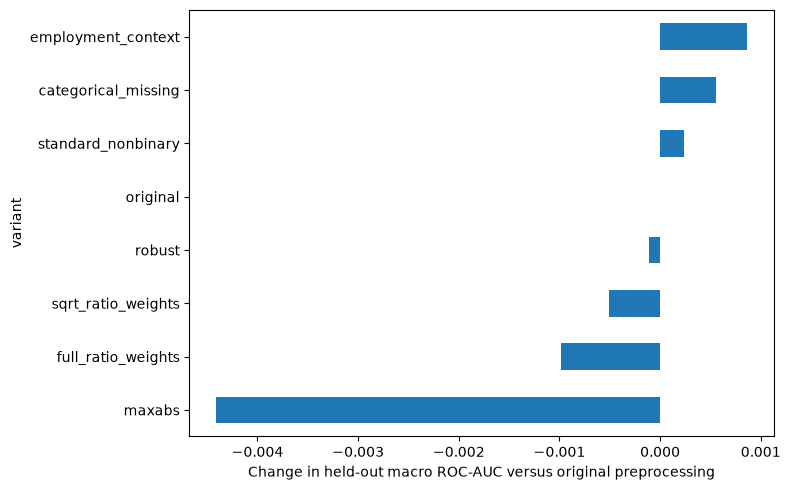

MLP runs reuse saved hyperparameters and fold epoch counts, capped by EDA_MLP_EPOCH_CAP; no HPO or new early-stopping loop. This is a fixed-budget screening comparison, not each scaler/imputer/weight at its independently tuned optimum.


In [19]:
eda_scaling_audit = []
for col in eda_numeric:
    values = eda_X[col].dropna()
    q01, q25, q50, q75, q99 = values.quantile([.01, .25, .5, .75, .99]).to_numpy()
    allowed = eda_allowed.get(col)
    kind = 'binary' if allowed == [0, 1] else 'bounded_survey_code' if allowed is not None else 'inspect'
    eda_scaling_audit.append({
        'feature': col, 'kind': kind, 'observed_n': len(values), 'n_unique': values.nunique(),
        'min': values.min(), 'p01': q01, 'p25': q25, 'median': q50, 'p75': q75,
        'p99': q99, 'max': values.max(), 'skew': values.skew(), 'iqr_zero': bool(q75 == q25),
        'log_screen_candidate': bool(kind == 'inspect' and values.nunique() > 20
                                     and values.min() >= 0 and values.skew() > 1),
    })
eda_scale_profile = pd.DataFrame(eda_scaling_audit)
eda_report('18_numeric_scaling_audit', eda_scale_profile, 30)
eda_log_screen = eda_scale_profile.query('log_screen_candidate')
if eda_log_screen.empty:
    eda_note('No natural continuous/log-scale candidate was identified. The documented numeric features are bounded survey codes; no log transform is applied.')
else:
    eda_note('Unexpected continuous-looking features need semantic review before any log transform: ' + ', '.join(eda_log_screen.feature))
eda_note('Scaling is tested on the two-hidden-layer PyTorch MLP, not on tree models. One-hot features and added flags remain unscaled. Standard_nonbinary does not rescale declared binary features; their missing values still use the same median imputation.')

eda_mlp_scaling_results = []
if EDA_RUN_MODEL_CHECKS and EDA_RUN_MLP_CHECKS:
    if 'torch' not in globals():
        raise ImportError('The PyTorch MLP diagnostics require torch in this kernel.')
    if isinstance(eda_best_trials['mlp'].get('user_attrs_best_epochs'), str):
        saved_epochs = np.asarray(eda_parse_list(eda_best_trials['mlp']['user_attrs_best_epochs']), dtype=int)
    else:
        saved_epochs = np.repeat(int(eda_json(EDA_ROOT / 'mlp_refit_epochs.json')['epochs']), EDA_N_SPLITS)
    eda_report('18_mlp_epoch_budget', pd.DataFrame({
        'fold': np.arange(1, EDA_CHECK_FOLDS + 1),
        'saved_epoch_count': saved_epochs[:EDA_CHECK_FOLDS],
        'diagnostic_epoch_count': [eda_mlp_epochs(f) for f in range(EDA_CHECK_FOLDS)],
    }))
    mlp_variants = [
        ('original', {}, 0.),
        ('categorical_missing', {'categorical': 'missing'}, 0.),
        ('employment_context', {'categorical': 'employment_context'}, 0.),
        ('maxabs', {'scaler': 'maxabs'}, 0.),
        ('robust', {'scaler': 'robust'}, 0.),
        ('standard_nonbinary', {'scaler': 'standard_nonbinary'}, 0.),
        ('sqrt_ratio_weights', {}, .5),
        ('full_ratio_weights', {}, 1.),
    ]
    for variant, preprocessing, power in mlp_variants:
        for fold in range(EDA_CHECK_FOLDS):
            probability = eda_extra_predict('mlp', fold, preprocessing, weight_power=power)
            eda_mlp_scaling_results.append(eda_extra_result('mlp', variant, fold, probability))
    eda_extra_summary(eda_mlp_scaling_results, '18_mlp_preprocessing', 'original')
    comparison = eda_tables['18_mlp_preprocessing_summary'].sort_values('delta_macro')
    comparison.plot.barh(x='variant', y='delta_macro', legend=False, figsize=(8, 5))
    plt.xlabel('Change in held-out macro ROC-AUC versus original preprocessing')
    eda_save_figure('18_mlp_preprocessing')
eda_note('MLP runs reuse saved hyperparameters and fold epoch counts, capped by EDA_MLP_EPOCH_CAP; no HPO or new early-stopping loop. This is a fixed-budget screening comparison, not each scaler/imputer/weight at its independently tuned optimum.')


## 19) Results bundle

In [20]:
eda_report('19_training_timing', pd.DataFrame(eda_timing, columns=['stage', 'variant', 'fold', 'target', 'seconds', 'cached']))
eda_decisions = []
for row in eda_candidates.head(4).itertuples(index=False):
    eda_decisions.append({'area': 'saved_predictions', 'candidate': row.candidate,
                          'mean_cv_auc': row.mean_cv_auc, 'delta': row.delta_vs_submitted,
                          'improved_folds': row.improved_folds, 'evaluation': 'reused 5-fold OOF; model-selection score'})
if EDA_RUN_MODEL_CHECKS:
    for key, area, name_col in [('13_feature_selection_summary', 'feature_selection', 'n_features'),
                                ('14_encoding_summary', 'representation', 'mode')]:
        for row in eda_tables[key].to_dict('records'):
            eda_decisions.append({'area': area, 'candidate': str(row[name_col]), 'mean_cv_auc': row['macro_auc'],
                                  'delta': row['delta_macro'], 'improved_folds': row['improved_folds'],
                                  'evaluation': f'fixed-parameter {EDA_CHECK_FOLDS}-fold screening'})

for key, area in [('15_employment_summary', 'employment_missingness'),
                  ('16_numeric_imputation_summary', 'numeric_imputation'),
                  ('17_class_weight_summary', 'class_weights'),
                  ('18_mlp_preprocessing_summary', 'mlp_preprocessing')]:
    if key not in eda_tables:
        continue
    for row in eda_tables[key].to_dict('records'):
        eda_decisions.append({'area': area, 'candidate': str(row['model']) + ':' + str(row['variant']),
                              'mean_cv_auc': row['macro_auc'], 'delta': row['delta_macro'],
                              'improved_folds': row['improved_folds'],
                              'evaluation': f'fixed-parameter {EDA_CHECK_FOLDS}-fold screening; not final tuned optimum'})
eda_report('19_extra_preprocessing_metadata', pd.DataFrame(eda_extra_prep_meta), 0)
eda_report('19_extra_fit_metadata', pd.DataFrame(eda_extra_fit_meta), 0)

eda_report('19_decision_summary', pd.DataFrame(eda_decisions), 25)
eda_manifest = {
    'generated_at_utc': datetime.now(timezone.utc).isoformat(),
    'seed': EDA_SEED, 'n_splits': EDA_N_SPLITS, 'diagnostic_folds': EDA_CHECK_FOLDS,
    'n_train': len(eda_X), 'n_test': len(eda_T), 'targets': eda_targets,
    'input_fingerprint': eda_fingerprint, 'versions': eda_versions,
    'xgboost_device': eda_xgb_device, 'catboost_diagnostic_backend': eda_cat_backend,
    'permutation_rows': EDA_PFI_ROWS, 'permutation_repeats': EDA_PFI_REPEATS,
    'saved_ensemble': eda_selection, 'elapsed_seconds': perf_counter() - eda_started,
    'new_experiments': {
        'revision': eda_extra_revision, 'knn_max_donors': EDA_KNN_MAX_DONORS,
        'knn_neighbors': EDA_KNN_NEIGHBORS, 'iterative_max_iter': EDA_IMPUTER_MAX_ITER,
        'mlp_checks': EDA_RUN_MLP_CHECKS, 'mlp_epoch_cap': EDA_MLP_EPOCH_CAP,
        'class_weight_powers': [0, .5, 1], 'employment_observed_values_preserved': True,
        'categorical_knn_imputation': False, 'automatic_outlier_removal': False,
        'log_transform_applied': False,
    },
    'notes': eda_notes,
    'sources': [
        'https://www.drivendata.org/competitions/66/flu-shot-learning/page/211/',
        'https://scikit-learn.org/stable/modules/permutation_importance.html',
        'https://scikit-learn.org/stable/common_pitfalls.html',
        'https://scikit-learn.org/stable/modules/impute.html',
        'https://scikit-learn.org/stable/modules/generated/sklearn.impute.IterativeImputer.html',
        'https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html',
        'https://scikit-learn.org/stable/modules/preprocessing.html',
        'https://scikit-learn.org/stable/modules/outlier_detection.html',
        'https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html',
        'https://catboost.ai/docs/en/references/training-parameters/common',
        'https://docs.pytorch.org/docs/stable/generated/torch.nn.modules.loss.BCEWithLogitsLoss.html',
        'https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier_get_feature_importance',
    ],
}
path = eda_out / 'run_manifest.json'
path.write_text(json.dumps(eda_manifest, indent=2), encoding='utf-8')
eda_files.append(path)
for name, params in eda_params.items():
    path = eda_out / f'input_{name}_best_params.json'
    path.write_text(json.dumps(params, indent=2), encoding='utf-8')
    eda_files.append(path)
for item in eda_inventory:
    current = hashlib.sha256((EDA_ROOT / item['file']).read_bytes()).hexdigest()
    if current != item['sha256']:
        raise RuntimeError(f'An input asset changed during EDA: {item["file"]}. Recheck the run before comparing results.')
archive_path = EDA_ROOT / 'eda_results.zip'
with zipfile.ZipFile(archive_path, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(set(eda_files)):
        archive.write(path, arcname=str(path.relative_to(eda_out)))
print(f'\nFinished in {(perf_counter() - eda_started) / 60:.1f} minutes.', flush=True)
print(f'Original assets unchanged. Results bundle: {archive_path}', flush=True)
print('The ZIP contains tables, plots, candidate predictions and aligned OOF predictions/labels, but no raw feature CSVs or fitted-model caches.', flush=True)
print('Return eda_results.zip for review. Candidate scores remain exploratory; no submission was replaced or uploaded.', flush=True)



19_training_timing: 108 rows


,stage,variant,fold,target,seconds,cached
0,catboost,all_features,1,h1n1_vaccine,74.012231,False
1,catboost,all_features,1,seasonal_vaccine,70.367274,False
2,catboost,all_features,2,h1n1_vaccine,73.867932,False
3,catboost,all_features,2,seasonal_vaccine,71.235807,False
4,catboost,all_features,3,h1n1_vaccine,68.735846,False
5,catboost,all_features,3,seasonal_vaccine,73.312132,False
6,catboost,top_25,1,h1n1_vaccine,71.799099,False
7,catboost,top_25,1,seasonal_vaccine,68.437411,False
8,catboost,top_15,1,h1n1_vaccine,45.946439,False
9,catboost,top_15,1,seasonal_vaccine,44.485891,False



19_extra_preprocessing_metadata: 54 rows

19_extra_fit_metadata: 54 rows

19_decision_summary: 35 rows


,area,candidate,mean_cv_auc,delta,improved_folds,evaluation
0,saved_predictions,coarse_target_specific,0.868471,0.003544,5,reused 5-fold OOF; model-selection score
1,saved_predictions,catboost_90_xgb_10,0.868321,0.003394,5,reused 5-fold OOF; model-selection score
2,saved_predictions,catboost_h1n1__equal_trees_seasonal,0.868312,0.003385,5,reused 5-fold OOF; model-selection score
3,saved_predictions,catboost_90_mlp_10,0.868309,0.003382,5,reused 5-fold OOF; model-selection score
4,feature_selection,15,0.866490,-0.002298,0,fixed-parameter 3-fold screening
5,feature_selection,25,0.868308,-0.000480,0,fixed-parameter 3-fold screening
6,representation,missing_flags,0.867988,0.016633,3,fixed-parameter 3-fold screening
7,representation,missing_and_known_opinions,0.867888,0.016534,3,fixed-parameter 3-fold screening
8,representation,paired_vaccine_features,0.854463,0.003108,3,fixed-parameter 3-fold screening
9,representation,opinions_known_scale,0.851515,0.000161,1,fixed-parameter 3-fold screening



Finished in 47.3 minutes.
Original assets unchanged. Results bundle: c:\Users\yana\Desktop\Library\AI\ai-competitions\2_H1N1\eda_results.zip
The ZIP contains tables, plots, candidate predictions and aligned OOF predictions/labels, but no raw feature CSVs or fitted-model caches.
Return eda_results.zip for review. Candidate scores remain exploratory; no submission was replaced or uploaded.


## 20) Done

In [23]:
import winsound

for freq in (880, 660, 440):
    winsound.Beep(freq, 250)